# Relatório unificado — SICOR Cerrado × Terras Indígenas

## Análise por `id_gleba2` | período de 2021 a 2025

Este notebook consolida, em um único fluxo, os três relatórios anteriores de Terras Indígenas. Ele lê a base expandida por `id_gleba2`, prepara as contagens sem duplicação indevida, gera tabelas, gráficos, histogramas e mapas e reúne todos os produtos em um único relatório Word.

### Unidade de análise adotada

- **Ocorrência espacial:** combinação única `id_gleba2 × Terra Indígena`.
- **Gleba:** `id_gleba2` distinto.
- **Operação:** `REF_BACEN` distinto, quando o campo estiver disponível.
- **Área acumulada:** soma das áreas das ocorrências `id_gleba2 × Terra Indígena`.
- **Área física única:** união geométrica das áreas de interseção, evitando dupla contagem de parcelas espacialmente coincidentes.

O relatório produzido é descritivo. A análise escrita e a discussão jurídica poderão ser incorporadas posteriormente ao capítulo de resultados.

In [1]:
# ============================================================
# 1. PREPARAR O AMBIENTE
# ============================================================

!pip install -q --upgrade geopandas pyogrio shapely geobr mapclassify python-docx

from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
from collections import OrderedDict
import inspect
import math
import re
import time
import unicodedata
import warnings
import zipfile

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.patches import Patch

from shapely import force_2d, make_valid, normalize as shapely_normalize
from shapely import wkt as shapely_wkt
from shapely.geometry import GeometryCollection, MultiPolygon, Polygon
from shapely.geometry.base import BaseGeometry
from shapely.ops import unary_union

import geobr

from docx import Document
from docx.enum.section import WD_ORIENT
from docx.enum.table import WD_CELL_VERTICAL_ALIGNMENT, WD_TABLE_ALIGNMENT
from docx.enum.text import WD_ALIGN_PARAGRAPH
from docx.enum.style import WD_STYLE_TYPE
from docx.enum.section import WD_SECTION
from docx.oxml import OxmlElement
from docx.oxml.ns import qn
from docx.shared import Inches, Pt, RGBColor

warnings.filterwarnings("ignore", category=UserWarning)

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 300)
pd.set_option("display.max_colwidth", 180)
pd.set_option("display.width", None)

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.titlesize": 14,
    "axes.labelsize": 10,
    "figure.dpi": 120,
    "savefig.dpi": 300,
})

print("Ambiente preparado.")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 2.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 48.1/48.1 kB 1.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 341.7/341.7 kB 10.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 47.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 479.0/479.0 kB 10.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 253.0/253.0 kB 8.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.5/21.5 MB 39.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.0/11.0 MB 65.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 29.6 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.2, but you have pandas 3.0.5 which is incompatible.
Mounted at /content/d

In [2]:
# ============================================================
# 2. CAMINHOS, PARÂMETROS E PASTA DE SAÍDA
# ============================================================

# Caminho informado no Windows:
# G:\Meu Drive\Colab Notebooks\fluxo\Envio\Arquivos gerados e relatorios\
# intersecoes\terras indígenas 2\resultados_por_id_gleba2\
# intersecao_sicor_tis_expandida_por_id_gleba2.csv

ARQUIVO_ENTRADA = Path(
    "/content/drive/MyDrive/Colab Notebooks/fluxo/Envio/"
    "Arquivos gerados e relatorios/intersecoes/terras indígenas 2/"
    "resultados_por_id_gleba2/"
    "intersecao_sicor_tis_expandida_por_id_gleba2.csv"
)

PASTA_SAIDA = ARQUIVO_ENTRADA.parent / "relatorio_unificado_terras_indigenas_id_gleba2"
PASTA_MAPAS = PASTA_SAIDA / "mapas"
PASTA_GRAFICOS = PASTA_SAIDA / "graficos_histogramas"
PASTA_TABELAS = PASTA_SAIDA / "tabelas"
PASTA_BASES = PASTA_SAIDA / "bases_analiticas"

for pasta in [PASTA_SAIDA, PASTA_MAPAS, PASTA_GRAFICOS, PASTA_TABELAS, PASTA_BASES]:
    pasta.mkdir(parents=True, exist_ok=True)

ARQUIVO_WORD = PASTA_SAIDA / "relatorio_unificado_sicor_terras_indigenas_2021_2025.docx"

# Se os downloads do geobr não funcionarem, informe arquivos locais abaixo.
ARQUIVO_CERRADO_LOCAL = None
ARQUIVO_ESTADOS_LOCAL = None
ARQUIVO_MUNICIPIOS_LOCAL = None

CRS_ENTRADA = "EPSG:4326"
CRS_GEOGRAFICO = "EPSG:4674"
CRS_AREA = "EPSG:5880"  # SIRGAS 2000 / Brazil Polyconic

TOP_N = 20
TOP_MAPA = 10
MAX_LINHAS_WORD = 30

if not ARQUIVO_ENTRADA.exists():
    raise FileNotFoundError(f"Arquivo de entrada não encontrado: {ARQUIVO_ENTRADA}")

print("Entrada:", ARQUIVO_ENTRADA)
print("Tamanho:", f"{ARQUIVO_ENTRADA.stat().st_size / (1024**2):,.2f} MB")
print("Saída:", PASTA_SAIDA)

Entrada: /content/drive/MyDrive/Colab Notebooks/fluxo/Envio/Arquivos gerados e relatorios/intersecoes/terras indígenas 2/resultados_por_id_gleba2/intersecao_sicor_tis_expandida_por_id_gleba2.csv
Tamanho: 71.35 MB
Saída: /content/drive/MyDrive/Colab Notebooks/fluxo/Envio/Arquivos gerados e relatorios/intersecoes/terras indígenas 2/resultados_por_id_gleba2/relatorio_unificado_terras_indigenas_id_gleba2


In [3]:
# ============================================================
# 3. FUNÇÕES DE LEITURA, NORMALIZAÇÃO E CONVERSÃO
# ============================================================

CODIFICACOES = ["utf-8-sig", "utf-8", "latin-1", "cp1252"]
SEPARADORES = [";", ",", "\t", "|"]


def remover_acentos(texto):
    return "".join(
        caractere
        for caractere in unicodedata.normalize("NFKD", str(texto))
        if not unicodedata.combining(caractere)
    )


def normalizar_nome_coluna(nome):
    nome = remover_acentos(nome).upper().strip().replace("#", "")
    nome = re.sub(r"[^A-Z0-9]+", "_", nome)
    return re.sub(r"_+", "_", nome).strip("_")


def tornar_nomes_unicos(nomes):
    contadores = {}
    saida = []
    for nome in nomes:
        numero = contadores.get(nome, 0)
        saida.append(nome if numero == 0 else f"{nome}_{numero + 1}")
        contadores[nome] = numero + 1
    return saida


def normalizar_colunas(df):
    df = df.copy()
    df.columns = tornar_nomes_unicos([normalizar_nome_coluna(c) for c in df.columns])
    return df


def detectar_csv(caminho):
    ultimo_erro = None
    for encoding in CODIFICACOES:
        for separador in SEPARADORES:
            try:
                teste = pd.read_csv(
                    caminho, sep=separador, encoding=encoding,
                    nrows=10, dtype=object, low_memory=False,
                )
                if teste.shape[1] > 1:
                    return encoding, separador
            except Exception as erro:
                ultimo_erro = erro
    raise RuntimeError(f"Não foi possível interpretar o CSV. Último erro: {ultimo_erro}")


def localizar_coluna(df_ou_colunas, candidatos, obrigatoria=False):
    colunas = list(df_ou_colunas.columns) if hasattr(df_ou_colunas, "columns") else list(df_ou_colunas)
    candidatos = [normalizar_nome_coluna(c) for c in candidatos]
    for candidato in candidatos:
        if candidato in colunas:
            return candidato
    for coluna in colunas:
        for candidato in candidatos:
            if candidato in coluna or coluna in candidato:
                return coluna
    if obrigatoria:
        raise KeyError(f"Nenhuma coluna encontrada para: {candidatos}")
    return None


def localizar_por_termos(df, positivos, negativos=None, prefixos=None):
    positivos = [normalizar_nome_coluna(x) for x in positivos]
    negativos = [normalizar_nome_coluna(x) for x in (negativos or [])]
    prefixos = [normalizar_nome_coluna(x) for x in (prefixos or [])]
    candidatas = []
    for coluna in df.columns:
        if prefixos and not any(coluna.startswith(p) for p in prefixos):
            continue
        if any(n in coluna for n in negativos):
            continue
        pontos = sum(p in coluna for p in positivos)
        if pontos:
            candidatas.append((pontos, -len(coluna), coluna))
    return max(candidatas)[2] if candidatas else None


def texto_limpo(serie):
    return (
        serie.astype("string")
        .str.strip()
        .str.replace(r"\.0$", "", regex=True)
        .replace({"": pd.NA, "nan": pd.NA, "None": pd.NA, "<NA>": pd.NA, "NULL": pd.NA})
    )


def numero_robusto(serie):
    serie = texto_limpo(serie)
    def converter(valor):
        if pd.isna(valor):
            return np.nan
        texto = str(valor).replace("R$", "").replace("%", "").replace(" ", "").strip()
        if "," in texto and "." in texto:
            texto = texto.replace(".", "").replace(",", ".") if texto.rfind(",") > texto.rfind(".") else texto.replace(",", "")
        elif "," in texto:
            texto = texto.replace(".", "").replace(",", ".")
        try:
            return float(texto)
        except Exception:
            return np.nan
    return serie.map(converter).astype(float)


def primeiro_nao_nulo(serie):
    valores = serie.dropna()
    return pd.NA if valores.empty else valores.iloc[0]


def unir_distintos(serie, limite=50):
    valores = sorted(set(serie.dropna().astype(str).str.strip()) - {""})
    if len(valores) > limite:
        valores = valores[:limite] + [f"... +{len(valores)-limite} valores"]
    return " | ".join(valores) if valores else pd.NA


def corrigir_geometria_poligonal(geometria):
    if geometria is None:
        return None
    try:
        if geometria.is_empty:
            return None
        geometria = force_2d(geometria)
        if not geometria.is_valid:
            geometria = make_valid(geometria)
    except Exception:
        try:
            geometria = geometria.buffer(0)
        except Exception:
            return None
    if isinstance(geometria, (Polygon, MultiPolygon)):
        try:
            return shapely_normalize(geometria)
        except Exception:
            return geometria
    if isinstance(geometria, GeometryCollection):
        partes = [g for g in geometria.geoms if isinstance(g, (Polygon, MultiPolygon)) and not g.is_empty]
        return corrigir_geometria_poligonal(unary_union(partes)) if partes else None
    return None


def converter_wkt(valor):
    if valor is None:
        return None
    try:
        if bool(pd.isna(valor)):
            return None
    except Exception:
        pass
    if isinstance(valor, BaseGeometry):
        return corrigir_geometria_poligonal(valor)
    if isinstance(valor, (bytes, bytearray, memoryview)):
        try:
            texto = bytes(valor).decode("utf-8")
        except UnicodeDecodeError:
            texto = bytes(valor).decode("latin-1", errors="ignore")
    else:
        texto = str(valor)
    texto = texto.strip().strip('"').strip("'")
    if not texto or texto.upper() in {"NAN", "NONE", "NULL", "<NA>"}:
        return None
    if texto.upper().startswith("SRID=") and ";" in texto:
        texto = texto.split(";", 1)[1]
    try:
        return corrigir_geometria_poligonal(shapely_wkt.loads(texto))
    except Exception:
        return None


def unir_geometrias_unicas(serie, crs=CRS_AREA):
    geometrias = [g for g in serie if g is not None and not g.is_empty]
    if not geometrias:
        return None
    try:
        return gpd.GeoSeries(geometrias, crs=crs).union_all()
    except (AttributeError, TypeError):
        return unary_union(geometrias)


def normalizar_gdf(gdf):
    crs = gdf.crs
    geometria_original = gdf.geometry.name
    mapa = dict(zip(gdf.columns, tornar_nomes_unicos([normalizar_nome_coluna(c) for c in gdf.columns])))
    gdf = gdf.rename(columns=mapa)
    gdf = gpd.GeoDataFrame(gdf, geometry=mapa[geometria_original], crs=crs)
    return gdf.rename_geometry("geometry") if gdf.geometry.name != "geometry" else gdf


print("Funções carregadas.")

Funções carregadas.


In [4]:
# ============================================================
# 4. LER A BASE E IDENTIFICAR AUTOMATICAMENTE OS CAMPOS
# ============================================================

encoding, separador = detectar_csv(ARQUIVO_ENTRADA)
dados_brutos = pd.read_csv(
    ARQUIVO_ENTRADA, sep=separador, encoding=encoding,
    dtype=object, low_memory=False,
)
dados_brutos = normalizar_colunas(dados_brutos)

COLUNA_ID_GLEBA = localizar_coluna(dados_brutos, ["ID_GLEBA2", "ID_GLEBA_2"], obrigatoria=True)
COLUNA_REF = localizar_coluna(dados_brutos, ["REF_BACEN", "CD_REF_BACEN"], obrigatoria=False)
COLUNA_ANO = localizar_coluna(
    dados_brutos,
    ["ANO", "ANO_BASE", "ANO_OPERACAO", "ANO_COPIA_BASE", "PRIMEIRO_ANO_OPERACAO", "ANO_REFERENCIA"],
    obrigatoria=False,
)
COLUNA_VALOR = localizar_coluna(
    dados_brutos,
    ["VALOR_TOTAL_CREDITO_R", "VALOR_CREDITO", "VALOR_FINANCIADO_R", "VL_PARC_CREDITO", "CREDITO_TOTAL"],
    obrigatoria=False,
)
COLUNA_TIPO_PRODUTOR = localizar_coluna(
    dados_brutos,
    ["TIPO_PRODUTOR_ANALISE", "TIPO_PRODUTOR_PORTE", "DESC_CATEG_EMITENTE", "CATEGORIA_EMITENTE", "PORTE_PRODUTOR"],
    obrigatoria=False,
)
COLUNA_PROGRAMA = localizar_coluna(dados_brutos, ["DESC_PROGRAMA", "GRUPO_PROGRAMA_CREDITO", "PROGRAMA", "CD_PROGRAMA"], obrigatoria=False)

COLUNA_TI_ID = localizar_coluna(
    dados_brutos,
    ["TI_ID_INTERNO", "TI_ID", "ID_TI", "ID_TERRA_INDIGENA", "CODIGO_TI", "COD_TI"],
    obrigatoria=True,
)
COLUNA_TI_NOME = localizar_coluna(
    dados_brutos,
    ["TI_TERRAI_NOM", "TI_TERRAI_NOME", "TI_NOME", "NOME_TI", "NOME_TERRA_INDIGENA", "TERRA_INDIGENA"],
    obrigatoria=False,
)
if COLUNA_TI_NOME is None:
    COLUNA_TI_NOME = localizar_por_termos(dados_brutos, ["NOME", "TERRAI", "TERRA"], ["AREA", "COD", "ID"], ["TI_"])

COLUNA_TI_FASE = localizar_coluna(dados_brutos, ["TI_FASE_TI", "TI_FASE", "FASE_REGULARIZACAO", "SITUACAO_FUNDIARIA", "SITUACAO_JURIDICA"], obrigatoria=False)
COLUNA_TI_MODALIDADE = localizar_coluna(dados_brutos, ["TI_MODALIDADE", "MODALIDADE", "TIPO_TI"], obrigatoria=False)
COLUNA_TI_ETNIA = localizar_coluna(dados_brutos, ["TI_ETNIA_NOME", "TI_ETNIA", "ETNIA", "POVO", "POVOS_INDIGENAS"], obrigatoria=False)
COLUNA_TI_UF = localizar_coluna(dados_brutos, ["TI_UF_SIGLA", "TI_UF", "UF_TI", "UF_TERRA_INDIGENA"], obrigatoria=False)
COLUNA_AREA_TOTAL_TI = localizar_coluna(dados_brutos, ["TI_AREA_TOTAL_HA", "AREA_TOTAL_TI_HA", "AREA_TERRA_INDIGENA_HA"], obrigatoria=False)

COLUNA_AREA_INTERSECAO = localizar_coluna(dados_brutos, ["AREA_INTERSECAO_HA", "AREA_SOBREPOSICAO_HA"], obrigatoria=False)
COLUNA_PERCENTUAL = localizar_coluna(dados_brutos, ["PERCENTUAL_GLEBA_INTERSECTADA", "PERCENTUAL_INTERSECAO", "PERC_INTERSECAO"], obrigatoria=False)
COLUNA_AREA_GLEBA = localizar_coluna(dados_brutos, ["AREA_GLEBA_HA_CALCULADA", "AREA_GLEBA_HA"], obrigatoria=False)
COLUNA_GEOM_INTERSECAO = localizar_coluna(
    dados_brutos,
    ["GEOMETRIA_INTERSECAO_WKT", "INTERSECAO_WKT", "GEOMETRIA_SOBREPOSICAO_WKT", "WKT_INTERSECAO"],
    obrigatoria=False,
)
COLUNA_GEOM_GLEBA = localizar_coluna(
    dados_brutos,
    ["GT_GEOMETRIA_REPRESENTATIVA", "GT_GEOMETRIA", "GEOMETRIA_GLEBA_WKT", "GEOMETRIA_GLEBA", "WKT_GLEBA"],
    obrigatoria=False,
)

campos_identificados = pd.DataFrame({
    "CAMPO_ANALITICO": [
        "id_gleba2", "REF_BACEN", "Ano", "Valor do crédito", "Tipo de produtor", "Programa",
        "ID da Terra Indígena", "Nome da Terra Indígena", "Fase", "Modalidade", "Povo/etnia",
        "UF da Terra Indígena", "Área total da TI", "Área da interseção", "% da gleba",
        "Área da gleba", "Geometria da interseção", "Geometria da gleba",
    ],
    "COLUNA_ENCONTRADA": [
        COLUNA_ID_GLEBA, COLUNA_REF, COLUNA_ANO, COLUNA_VALOR, COLUNA_TIPO_PRODUTOR, COLUNA_PROGRAMA,
        COLUNA_TI_ID, COLUNA_TI_NOME, COLUNA_TI_FASE, COLUNA_TI_MODALIDADE, COLUNA_TI_ETNIA,
        COLUNA_TI_UF, COLUNA_AREA_TOTAL_TI, COLUNA_AREA_INTERSECAO, COLUNA_PERCENTUAL,
        COLUNA_AREA_GLEBA, COLUNA_GEOM_INTERSECAO, COLUNA_GEOM_GLEBA,
    ],
})

print(f"Arquivo lido: {len(dados_brutos):,} linhas × {dados_brutos.shape[1]:,} colunas")
print("Codificação:", encoding, "| Separador:", repr(separador))
display(campos_identificados)

Arquivo lido: 660 linhas × 53 colunas
Codificação: utf-8-sig | Separador: ';'


,CAMPO_ANALITICO,COLUNA_ENCONTRADA
0,id_gleba2,ID_GLEBA2
1,REF_BACEN,REF_BACEN
2,Ano,ANO_BASE
3,Valor do crédito,VL_PARC_CREDITO
4,Tipo de produtor,TIPO_PRODUTOR_ANALISE
5,Programa,DESC_PROGRAMA
6,ID da Terra Indígena,TI_ID_INTERNO
7,Nome da Terra Indígena,TI_TERRAI_NOM
8,Fase,TI_FASE_TI
9,Modalidade,TI_MODALIDADE


In [5]:
# ============================================================
# 5. PREPARAR DIMENSÕES, PERÍODO E CLASSIFICAÇÕES
# ============================================================

dados = dados_brutos.copy()
dados["_ID_GLEBA2"] = texto_limpo(dados[COLUNA_ID_GLEBA])
dados["_TI_ID"] = texto_limpo(dados[COLUNA_TI_ID])
dados["_REF_BACEN"] = texto_limpo(dados[COLUNA_REF]) if COLUNA_REF else pd.Series(pd.NA, index=dados.index, dtype="string")

dados["_ANO"] = (
    pd.to_numeric(texto_limpo(dados[COLUNA_ANO]), errors="coerce").astype("Int64")
    if COLUNA_ANO else pd.Series(pd.NA, index=dados.index, dtype="Int64")
)
dados.loc[~dados["_ANO"].between(2000, 2100, inclusive="both"), "_ANO"] = pd.NA

dados["_VALOR_R"] = numero_robusto(dados[COLUNA_VALOR]) if COLUNA_VALOR else np.nan
dados["_AREA_INTERSECAO_CSV_HA"] = numero_robusto(dados[COLUNA_AREA_INTERSECAO]) if COLUNA_AREA_INTERSECAO else np.nan
dados["_PERCENTUAL_GLEBA"] = numero_robusto(dados[COLUNA_PERCENTUAL]) if COLUNA_PERCENTUAL else np.nan
dados["_AREA_GLEBA_CSV_HA"] = numero_robusto(dados[COLUNA_AREA_GLEBA]) if COLUNA_AREA_GLEBA else np.nan
dados["_AREA_TOTAL_TI_HA"] = numero_robusto(dados[COLUNA_AREA_TOTAL_TI]) if COLUNA_AREA_TOTAL_TI else np.nan

dados["_TI_NOME"] = texto_limpo(dados[COLUNA_TI_NOME]) if COLUNA_TI_NOME else pd.Series(pd.NA, index=dados.index, dtype="string")
dados["_TI_NOME"] = dados["_TI_NOME"].fillna("Terra Indígena sem nome - ID " + dados["_TI_ID"].astype(str))
dados["_TI_FASE"] = texto_limpo(dados[COLUNA_TI_FASE]).fillna("Não informado") if COLUNA_TI_FASE else "Não informado"
dados["_TI_MODALIDADE"] = texto_limpo(dados[COLUNA_TI_MODALIDADE]).fillna("Não informado") if COLUNA_TI_MODALIDADE else "Não informado"
dados["_TI_ETNIA"] = texto_limpo(dados[COLUNA_TI_ETNIA]).fillna("Não informado") if COLUNA_TI_ETNIA else "Não informado"
dados["_TI_UF"] = texto_limpo(dados[COLUNA_TI_UF]).fillna("Não informado") if COLUNA_TI_UF else "Não informado"
dados["_PROGRAMA"] = texto_limpo(dados[COLUNA_PROGRAMA]).fillna("Não informado") if COLUNA_PROGRAMA else "Não informado"

texto_tipo = texto_limpo(dados[COLUNA_TIPO_PRODUTOR]).fillna("") if COLUNA_TIPO_PRODUTOR else pd.Series("", index=dados.index)
texto_classificacao = (
    texto_tipo.astype(str) + " | " + dados["_PROGRAMA"].astype(str)
).map(remover_acentos).str.upper()

condicao_pronaf = texto_classificacao.str.contains(r"PRONAF|PEQUEN|GRUPO\s*B", regex=True, na=False)
condicao_pronamp = texto_classificacao.str.contains(r"PRONAMP|MEDIO", regex=True, na=False)
dados["_TIPO_PRODUTOR"] = np.select(
    [condicao_pronaf, condicao_pronamp],
    ["Pronaf / pequeno produtor", "Pronamp / médio produtor"],
    default="Demais produtores",
)

dados = dados.dropna(subset=["_ID_GLEBA2", "_TI_ID"]).copy()

anos_validos = sorted(dados["_ANO"].dropna().astype(int).unique().tolist())
if anos_validos:
    ANO_INICIAL, ANO_FINAL = min(anos_validos), max(anos_validos)
    PERIODO = str(ANO_INICIAL) if ANO_INICIAL == ANO_FINAL else f"{ANO_INICIAL} a {ANO_FINAL}"
    PERIODO_CURTO = str(ANO_INICIAL) if ANO_INICIAL == ANO_FINAL else f"{ANO_INICIAL}–{ANO_FINAL}"
else:
    ANO_INICIAL, ANO_FINAL = None, None
    PERIODO = "período não identificado na base"
    PERIODO_CURTO = "período não identificado"

if not anos_validos:
    raise ValueError(
        "Não foi possível identificar o período. Acrescente o nome correto da coluna anual aos candidatos de COLUNA_ANO."
    )

print("Período identificado:", PERIODO)
print("Linhas com id_gleba2 e TI válidos:", f"{len(dados):,}")

Período identificado: 2021 a 2025
Linhas com id_gleba2 e TI válidos: 660


In [6]:
# ============================================================
# 6. CONVERTER GEOMETRIAS E CRIAR AS BASES SEM DUPLICAÇÃO
# ============================================================

if COLUNA_GEOM_INTERSECAO is None:
    raise KeyError(
        "A base precisa conter a geometria WKT da interseção para produzir os mapas e a área física única. "
        "Acrescente o nome correto da coluna aos candidatos de COLUNA_GEOM_INTERSECAO."
    )

geometrias_intersecao = [converter_wkt(v) for v in dados[COLUNA_GEOM_INTERSECAO].astype(object).tolist()]
gdf = gpd.GeoDataFrame(
    dados.copy(),
    geometry=gpd.GeoSeries(geometrias_intersecao, index=dados.index, crs=CRS_ENTRADA),
    crs=CRS_ENTRADA,
)
gdf = gdf[gdf.geometry.notna() & ~gdf.geometry.is_empty].copy()

gdf_area = gdf.to_crs(CRS_AREA)
gdf["_AREA_INTERSECAO_GEOM_HA"] = (gdf_area.geometry.area / 10_000).to_numpy()

# Uma ocorrência espacial é uma combinação id_gleba2 × Terra Indígena.
# A maior geometria é mantida caso existam repetições técnicas da mesma combinação.
linhas_geometricas_validas = len(gdf)
gdf_ocorrencias = (
    gdf.sort_values("_AREA_INTERSECAO_GEOM_HA", ascending=False)
    .drop_duplicates(["_ID_GLEBA2", "_TI_ID"], keep="first")
    .reset_index(drop=True)
)
duplicacoes_ocorrencia_removidas = linhas_geometricas_validas - len(gdf_ocorrencias)

# Uma gleba espacial: um único id_gleba2.
gdf_glebas_intersecao = (
    gdf_ocorrencias.sort_values("_AREA_INTERSECAO_GEOM_HA", ascending=False)
    .drop_duplicates("_ID_GLEBA2", keep="first")
    .reset_index(drop=True)
)

# Geometria integral da gleba, quando disponível.
if COLUNA_GEOM_GLEBA:
    candidatos_gleba = (
        dados.sort_values("_ID_GLEBA2")
        .drop_duplicates("_ID_GLEBA2", keep="first")
        .copy()
    )
    geom_glebas = [converter_wkt(v) for v in candidatos_gleba[COLUNA_GEOM_GLEBA].astype(object).tolist()]
    gdf_glebas = gpd.GeoDataFrame(
        candidatos_gleba,
        geometry=gpd.GeoSeries(geom_glebas, index=candidatos_gleba.index, crs=CRS_ENTRADA),
        crs=CRS_ENTRADA,
    )
    gdf_glebas = gdf_glebas[gdf_glebas.geometry.notna() & ~gdf_glebas.geometry.is_empty].copy()
    gdf_glebas["_AREA_GLEBA_GEOM_HA"] = (
        gdf_glebas.to_crs(CRS_AREA).geometry.area / 10_000
    ).to_numpy()
else:
    gdf_glebas = gdf_glebas_intersecao.copy()
    gdf_glebas["_AREA_GLEBA_GEOM_HA"] = gdf_glebas["_AREA_GLEBA_CSV_HA"]

# Base por operação: cada REF_BACEN aparece uma única vez nos totais financeiros.
if COLUNA_REF:
    base_operacoes = (
        dados.dropna(subset=["_REF_BACEN"])
        .sort_values(["_REF_BACEN", "_ANO"])
        .drop_duplicates("_REF_BACEN", keep="first")
        .copy()
    )
else:
    base_operacoes = pd.DataFrame(columns=dados.columns)

print("Geometrias de interseção válidas:", f"{linhas_geometricas_validas:,}")
print("Ocorrências únicas id_gleba2 × TI:", f"{len(gdf_ocorrencias):,}")
print("Repetições técnicas removidas:", f"{duplicacoes_ocorrencia_removidas:,}")
print("Glebas distintas (id_gleba2):", f"{gdf_ocorrencias['_ID_GLEBA2'].nunique():,}")
print("Operações distintas (REF_BACEN):", f"{base_operacoes['_REF_BACEN'].nunique():,}" if not base_operacoes.empty else "não disponível")

Geometrias de interseção válidas: 660
Ocorrências únicas id_gleba2 × TI: 569
Repetições técnicas removidas: 91
Glebas distintas (id_gleba2): 554
Operações distintas (REF_BACEN): 476


In [7]:
# ============================================================
# 7. CARREGAR CERRADO, ESTADOS E MUNICÍPIOS
# ============================================================

def carregar_vetor(caminho_local, funcao_geobr, rotulo, *args, **kwargs):
    """
    Lê uma malha local ou tenta baixá-la novamente pelo geobr.

    cache=False evita reutilizar um arquivo temporário corrompido. O parâmetro
    só é acrescentado quando existe na versão instalada da função do geobr.
    """
    if caminho_local:
        caminho = Path(caminho_local)
        if not caminho.exists():
            raise FileNotFoundError(f"Arquivo vetorial local não encontrado: {caminho}")
        print(f"Lendo {rotulo} do arquivo local: {caminho}")
        return gpd.read_file(caminho)

    parametros = inspect.signature(funcao_geobr).parameters
    argumentos = dict(kwargs)

    if "cache" in parametros:
        argumentos["cache"] = False

    if "show_progress" in parametros:
        argumentos["show_progress"] = True

    ultimo_erro = None

    for tentativa in range(1, 4):
        try:
            print(f"Baixando {rotulo} pelo geobr — tentativa {tentativa}/3...")
            camada = funcao_geobr(*args, **argumentos)

            if camada is None or camada.empty:
                raise RuntimeError(f"O geobr retornou a malha de {rotulo} vazia.")

            print(f"{rotulo.capitalize()} carregado: {len(camada):,} feições.")
            return camada

        except (ConnectionError, OSError, RuntimeError) as erro:
            ultimo_erro = erro
            print(f"Falha na tentativa {tentativa}: {erro}")

            if tentativa < 3:
                time.sleep(2 * tentativa)

    raise ConnectionError(
        f"Não foi possível baixar {rotulo} após três tentativas. "
        "A conexão do Colab com o servidor do geobr pode estar instável. "
        "Baixe essa malha, salve-a no Google Drive e informe seu caminho "
        "na variável local correspondente da célula 2. "
        f"Último erro: {ultimo_erro}"
    )


biomas = normalizar_gdf(
    carregar_vetor(
        ARQUIVO_CERRADO_LOCAL,
        geobr.read_biomes,
        "biomas",
        year=2019,
        simplified=True,
    )
)
coluna_bioma = localizar_coluna(biomas, ["NAME_BIOME", "NOME_BIOMA", "BIOME", "BIOMA", "NAME"], obrigatoria=True)
cerrado = biomas[
    biomas[coluna_bioma].astype(str).map(remover_acentos).str.upper().str.contains("CERRADO", na=False)
].copy()
cerrado = cerrado.set_crs(CRS_GEOGRAFICO, allow_override=True) if cerrado.crs is None else cerrado.to_crs(CRS_GEOGRAFICO)

estados = normalizar_gdf(
    carregar_vetor(
        ARQUIVO_ESTADOS_LOCAL,
        geobr.read_state,
        "estados",
        year=2020,
        simplified=True,
    )
)
coluna_uf_estado = localizar_coluna(estados, ["ABBREV_STATE", "SIGLA_UF", "SG_UF", "UF"], obrigatoria=True)
estados["UF"] = texto_limpo(estados[coluna_uf_estado]).str.upper()
estados = estados.set_crs(CRS_GEOGRAFICO, allow_override=True) if estados.crs is None else estados.to_crs(CRS_GEOGRAFICO)

municipios = normalizar_gdf(
    carregar_vetor(
        ARQUIVO_MUNICIPIOS_LOCAL,
        geobr.read_municipality,
        "municípios",
        code_muni="all",
        year=2020,
        simplified=True,
    )
)
coluna_codigo_muni = localizar_coluna(municipios, ["CODE_MUNI", "COD_MUN", "CD_MUN", "CODIGO_MUNICIPIO"], obrigatoria=True)
coluna_nome_muni = localizar_coluna(municipios, ["NAME_MUNI", "NOME_MUNICIPIO", "NM_MUN", "MUNICIPIO"], obrigatoria=True)
coluna_uf_muni = localizar_coluna(municipios, ["ABBREV_STATE", "SIGLA_UF", "SG_UF", "UF"], obrigatoria=True)
municipios["COD_MUNICIPIO"] = texto_limpo(municipios[coluna_codigo_muni])
municipios["MUNICIPIO"] = texto_limpo(municipios[coluna_nome_muni])
municipios["UF"] = texto_limpo(municipios[coluna_uf_muni]).str.upper()
municipios = municipios.set_crs(CRS_GEOGRAFICO, allow_override=True) if municipios.crs is None else municipios.to_crs(CRS_GEOGRAFICO)

try:
    geometria_analise = gdf_ocorrencias.to_crs(CRS_GEOGRAFICO).geometry.union_all()
except AttributeError:
    geometria_analise = unary_union(gdf_ocorrencias.to_crs(CRS_GEOGRAFICO).geometry)

estados_relevantes = estados[estados.geometry.intersects(geometria_analise)].copy()
municipios_relevantes = municipios[municipios.geometry.intersects(geometria_analise)].copy()

print("Estados relevantes:", len(estados_relevantes))
print("Municípios relevantes:", len(municipios_relevantes))

Baixando biomas pelo geobr — tentativa 1/3...


/usr/local/lib/python3.12/dist-packages/urllib3/connectionpool.py:1097: InsecureRequestWarning: Unverified HTTPS request is being made to host 'github.com'. Adding certificate verification is strongly advised. See: https://urllib3.readthedocs.io/en/latest/advanced-usage.html#tls-warnings
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/urllib3/connectionpool.py:1097: InsecureRequestWarning: Unverified HTTPS request is being made to host 'www.ipea.gov.br'. Adding certificate verification is strongly advised. See: https://urllib3.readthedocs.io/en/latest/advanced-usage.html#tls-warnings
  warnings.warn(


Falha na tentativa 1: A file may have been corrupted during download. Please try again or report at https://github.com/ipea/geobr/issues
Baixando biomas pelo geobr — tentativa 2/3...


/usr/local/lib/python3.12/dist-packages/urllib3/connectionpool.py:1097: InsecureRequestWarning: Unverified HTTPS request is being made to host 'github.com'. Adding certificate verification is strongly advised. See: https://urllib3.readthedocs.io/en/latest/advanced-usage.html#tls-warnings
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/urllib3/connectionpool.py:1097: InsecureRequestWarning: Unverified HTTPS request is being made to host 'www.ipea.gov.br'. Adding certificate verification is strongly advised. See: https://urllib3.readthedocs.io/en/latest/advanced-usage.html#tls-warnings
  warnings.warn(


Falha na tentativa 2: A file may have been corrupted during download. Please try again or report at https://github.com/ipea/geobr/issues
Baixando biomas pelo geobr — tentativa 3/3...


/usr/local/lib/python3.12/dist-packages/urllib3/connectionpool.py:1097: InsecureRequestWarning: Unverified HTTPS request is being made to host 'github.com'. Adding certificate verification is strongly advised. See: https://urllib3.readthedocs.io/en/latest/advanced-usage.html#tls-warnings
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/urllib3/connectionpool.py:1097: InsecureRequestWarning: Unverified HTTPS request is being made to host 'release-assets.githubusercontent.com'. Adding certificate verification is strongly advised. See: https://urllib3.readthedocs.io/en/latest/advanced-usage.html#tls-warnings
  warnings.warn(
biomes_2019_simplified.parquet: 100%|██████████| 3.14M/3.14M [00:00<00:00, 41.4MB/s]


... (4 outputs left out)

/usr/local/lib/python3.12/dist-packages/urllib3/connectionpool.py:1097: InsecureRequestWarning: Unverified HTTPS request is being made to host 'github.com'. Adding certificate verification is strongly advised. See: https://urllib3.readthedocs.io/en/latest/advanced-usage.html#tls-warnings
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/urllib3/connectionpool.py:1097: InsecureRequestWarning: Unverified HTTPS request is being made to host 'release-assets.githubusercontent.com'. Adding certificate verification is strongly advised. See: https://urllib3.readthedocs.io/en/latest/advanced-usage.html#tls-warnings
  warnings.warn(
states_2020_simplified.parquet: 100%|██████████| 1.72M/1.72M [00:00<00:00, 75.0MB/s]
/usr/local/lib/python3.12/dist-packages/urllib3/connectionpool.py:1097: InsecureRequestWarning: Unverified HTTPS request is being made to host 'github.com'. Adding certificate verification is strongly advised. See: https://urllib3.readthedocs.io/en/latest/advanced-usage.html#t

Estados carregado: 27 feições.
Baixando municípios pelo geobr — tentativa 1/3...


/usr/local/lib/python3.12/dist-packages/urllib3/connectionpool.py:1097: InsecureRequestWarning: Unverified HTTPS request is being made to host 'release-assets.githubusercontent.com'. Adding certificate verification is strongly advised. See: https://urllib3.readthedocs.io/en/latest/advanced-usage.html#tls-warnings
  warnings.warn(
municipalities_2020_simplified.parquet: 100%|██████████| 20.2M/20.2M [00:00<00:00, 56.7MB/s]


Municípios carregado: 5,570 feições.
Estados relevantes: 7
Municípios relevantes: 48


In [8]:
# ============================================================
# 8. ATRIBUIR UF À GLEBA E DIVIDIR AS INTERSEÇÕES POR MUNICÍPIO
# ============================================================

# UF da gleba pelo ponto representativo.
pontos_glebas = gdf_glebas[["_ID_GLEBA2", "geometry"]].to_crs(CRS_GEOGRAFICO).copy()
pontos_glebas["geometry"] = pontos_glebas.geometry.representative_point()
associacao_uf = gpd.sjoin(
    pontos_glebas,
    estados[["UF", "geometry"]],
    how="left",
    predicate="within",
).drop(columns="index_right", errors="ignore")
associacao_uf = associacao_uf.drop_duplicates("_ID_GLEBA2", keep="first")
mapa_uf_gleba = associacao_uf.set_index("_ID_GLEBA2")["UF"]

gdf_ocorrencias["_UF_GLEBA"] = gdf_ocorrencias["_ID_GLEBA2"].map(mapa_uf_gleba).fillna("Não identificada")
gdf_glebas["_UF_GLEBA"] = gdf_glebas["_ID_GLEBA2"].map(mapa_uf_gleba).fillna("Não identificada")

# Corte das áreas de interseção pelas fronteiras municipais.
intersecoes_area = gdf_ocorrencias.to_crs(CRS_AREA).copy().reset_index(drop=True)

# Os nomes são temporariamente alterados para evitar colisões com eventuais
# colunas homônimas existentes na base de interseções.
municipios_area = (
    municipios_relevantes[["COD_MUNICIPIO", "MUNICIPIO", "UF", "geometry"]]
    .rename(columns={
        "COD_MUNICIPIO": "_COD_MUNICIPIO_CORTE",
        "MUNICIPIO": "_MUNICIPIO_CORTE",
        "UF": "_UF_CORTE",
    })
    .to_crs(CRS_AREA)
    .copy()
    .reset_index(drop=True)
)

# Identificador explícito: não depende de index_right, index_municipio ou de
# qualquer outro nome que o GeoPandas atribua ao índice da camada da direita.
municipios_area["_INDICE_MUNICIPIO_CORTE"] = np.arange(len(municipios_area))

candidatos_municipais = gpd.sjoin(
    intersecoes_area,
    municipios_area,
    how="inner",
    predicate="intersects",
).reset_index(drop=True)

if candidatos_municipais.empty:
    raise RuntimeError(
        "Nenhuma interseção foi associada à malha municipal. "
        "Verifique os CRS e a extensão espacial das camadas."
    )

indices_municipios = candidatos_municipais["_INDICE_MUNICIPIO_CORTE"].astype(int).to_numpy()
geom_municipios = municipios_area.geometry.iloc[indices_municipios].reset_index(drop=True)
geom_intersecoes = candidatos_municipais.geometry.reset_index(drop=True)

partes = geom_intersecoes.intersection(
    gpd.GeoSeries(geom_municipios.to_list(), crs=CRS_AREA)
)
mascara = partes.notna() & ~partes.is_empty

atributos = (
    candidatos_municipais.loc[mascara.to_numpy()]
    .drop(
        columns=[
            "index_right",
            "index_municipio",
            "geometry",
            "_INDICE_MUNICIPIO_CORTE",
            "COD_MUNICIPIO",
            "MUNICIPIO",
            "UF",
        ],
        errors="ignore",
    )
    .rename(columns={
        "_COD_MUNICIPIO_CORTE": "COD_MUNICIPIO",
        "_MUNICIPIO_CORTE": "MUNICIPIO",
        "_UF_CORTE": "UF",
    })
    .reset_index(drop=True)
)
partes = partes.loc[mascara].reset_index(drop=True)
gdf_municipal = gpd.GeoDataFrame(atributos, geometry=gpd.GeoSeries(partes.to_list(), crs=CRS_AREA), crs=CRS_AREA)
gdf_municipal["_AREA_PARTE_MUNICIPIO_HA"] = gdf_municipal.geometry.area / 10_000
gdf_municipal = gdf_municipal[gdf_municipal["_AREA_PARTE_MUNICIPIO_HA"] > 0].copy()

area_partes = gdf_municipal["_AREA_PARTE_MUNICIPIO_HA"].sum()
area_ocorrencias = intersecoes_area.geometry.area.sum() / 10_000
diferenca_municipal = area_partes - area_ocorrencias

print("Partes municipais:", f"{len(gdf_municipal):,}")
print("Área das ocorrências (ha):", f"{area_ocorrencias:,.4f}")
print("Área após corte municipal (ha):", f"{area_partes:,.4f}")
print("Diferença de validação (ha):", f"{diferenca_municipal:,.6f}")

Partes municipais: 595
Área das ocorrências (ha): 51,554.9376
Área após corte municipal (ha): 51,554.9376
Diferença de validação (ha): -0.000000


In [9]:
# ============================================================
# 9. CALCULAR INDICADORES E TABELAS-RESUMO
# ============================================================

geom_total_unica = unir_geometrias_unicas(intersecoes_area.geometry)
area_fisica_unica_total_ha = geom_total_unica.area / 10_000 if geom_total_unica is not None else 0
area_acumulada_total_ha = gdf_ocorrencias["_AREA_INTERSECAO_GEOM_HA"].sum()

total_glebas = gdf_ocorrencias["_ID_GLEBA2"].nunique()
total_tis = gdf_ocorrencias["_TI_ID"].nunique()
total_refs = base_operacoes["_REF_BACEN"].nunique() if not base_operacoes.empty else np.nan
total_valor = base_operacoes["_VALOR_R"].sum(min_count=1) if not base_operacoes.empty else np.nan

resumo_geral = pd.DataFrame([
    {"INDICADOR": "Linhas originais do CSV", "VALOR": len(dados_brutos)},
    {"INDICADOR": "Linhas com id_gleba2 e TI preenchidos", "VALOR": len(dados)},
    {"INDICADOR": "Geometrias de interseção válidas", "VALOR": linhas_geometricas_validas},
    {"INDICADOR": "Ocorrências únicas id_gleba2 × TI", "VALOR": len(gdf_ocorrencias)},
    {"INDICADOR": "Glebas distintas (id_gleba2)", "VALOR": total_glebas},
    {"INDICADOR": "Terras Indígenas distintas", "VALOR": total_tis},
    {"INDICADOR": "Operações distintas (REF_BACEN)", "VALOR": total_refs},
    {"INDICADOR": "Área acumulada das ocorrências (ha)", "VALOR": area_acumulada_total_ha},
    {"INDICADOR": "Área física única de sobreposição (ha)", "VALOR": area_fisica_unica_total_ha},
    {"INDICADOR": "Valor das operações sem repetição por REF_BACEN (R$)", "VALOR": total_valor},
])

qualidade = pd.DataFrame([
    {"VERIFICACAO": "Período identificado", "RESULTADO": PERIODO},
    {"VERIFICACAO": "Linhas sem id_gleba2 ou TI removidas", "RESULTADO": len(dados_brutos) - len(dados)},
    {"VERIFICACAO": "Geometrias inválidas/ausentes", "RESULTADO": len(dados) - linhas_geometricas_validas},
    {"VERIFICACAO": "Repetições id_gleba2 × TI removidas", "RESULTADO": duplicacoes_ocorrencia_removidas},
    {"VERIFICACAO": "Ocorrências com área geométrica não positiva", "RESULTADO": int((gdf_ocorrencias["_AREA_INTERSECAO_GEOM_HA"] <= 0).sum())},
    {"VERIFICACAO": "Glebas sem UF espacial", "RESULTADO": int(gdf_glebas["_UF_GLEBA"].eq("Não identificada").sum())},
    {"VERIFICACAO": "Diferença do corte municipal (ha)", "RESULTADO": diferenca_municipal},
])


def resumo_com_area_unica(df_gdf, dimensoes, id_unidade="_ID_GLEBA2", area_col="_AREA_INTERSECAO_GEOM_HA"):
    base = (
        df_gdf.groupby(dimensoes, dropna=False, as_index=False)
        .agg(
            QUANTIDADE_GLEBAS=(id_unidade, "nunique"),
            QUANTIDADE_TIS=("_TI_ID", "nunique"),
            QUANTIDADE_OCORRENCIAS=(id_unidade, "size"),
            AREA_ACUMULADA_HA=(area_col, "sum"),
        )
    )
    chave = dimensoes[0] if len(dimensoes) == 1 else dimensoes
    geoms = df_gdf.to_crs(CRS_AREA).groupby(dimensoes, dropna=False)["geometry"].apply(unir_geometrias_unicas)
    areas = geoms.map(lambda g: g.area / 10_000 if g is not None else 0).rename("AREA_FISICA_UNICA_HA")
    if len(dimensoes) == 1:
        return base.merge(areas, left_on=dimensoes[0], right_index=True, how="left")
    return base.merge(areas.reset_index(), on=dimensoes, how="left")


resumo_ti = resumo_com_area_unica(
    gdf_ocorrencias,
    ["_TI_ID", "_TI_NOME", "_TI_FASE", "_TI_MODALIDADE", "_TI_ETNIA", "_TI_UF"],
)
area_total_ti = gdf_ocorrencias.groupby("_TI_ID")["_AREA_TOTAL_TI_HA"].max()
resumo_ti["AREA_TOTAL_TI_HA"] = resumo_ti["_TI_ID"].map(area_total_ti)
resumo_ti["PERCENTUAL_TI_COM_SOBREPOSICAO"] = np.where(
    resumo_ti["AREA_TOTAL_TI_HA"] > 0,
    resumo_ti["AREA_FISICA_UNICA_HA"] / resumo_ti["AREA_TOTAL_TI_HA"] * 100,
    np.nan,
)
resumo_ti = resumo_ti.sort_values("AREA_FISICA_UNICA_HA", ascending=False)

resumo_fase = resumo_com_area_unica(gdf_ocorrencias, ["_TI_FASE"]).sort_values("AREA_FISICA_UNICA_HA", ascending=False)
resumo_modalidade = resumo_com_area_unica(gdf_ocorrencias, ["_TI_MODALIDADE"]).sort_values("AREA_FISICA_UNICA_HA", ascending=False)
resumo_etnia = resumo_com_area_unica(gdf_ocorrencias, ["_TI_ETNIA"]).sort_values("AREA_FISICA_UNICA_HA", ascending=False)
# Município: contagens e área física após o corte espacial.
resumo_municipio_base = (
    gdf_municipal.groupby(["COD_MUNICIPIO", "MUNICIPIO", "UF"], dropna=False, as_index=False)
    .agg(
        QUANTIDADE_GLEBAS=("_ID_GLEBA2", "nunique"),
        QUANTIDADE_TIS=("_TI_ID", "nunique"),
        AREA_ACUMULADA_HA=("_AREA_PARTE_MUNICIPIO_HA", "sum"),
    )
)
area_unica_municipio = (
    gdf_municipal.groupby("COD_MUNICIPIO")["geometry"]
    .apply(unir_geometrias_unicas)
    .map(lambda g: g.area / 10_000 if g is not None else 0)
)
resumo_municipio = resumo_municipio_base.merge(
    area_unica_municipio.rename("AREA_FISICA_UNICA_HA"),
    left_on="COD_MUNICIPIO", right_index=True, how="left",
).sort_values("AREA_FISICA_UNICA_HA", ascending=False)

# UF espacial: calculada a partir das partes efetivamente situadas em cada estado.
# Uma gleba que atravesse uma divisa pode ser contada nas duas UFs, sem duplicar sua área.
resumo_uf_base = (
    gdf_municipal.groupby("UF", dropna=False, as_index=False)
    .agg(
        QUANTIDADE_GLEBAS=("_ID_GLEBA2", "nunique"),
        QUANTIDADE_TIS=("_TI_ID", "nunique"),
        AREA_ACUMULADA_HA=("_AREA_PARTE_MUNICIPIO_HA", "sum"),
    )
)
area_unica_uf = (
    gdf_municipal.groupby("UF")["geometry"]
    .apply(unir_geometrias_unicas)
    .map(lambda g: g.area / 10_000 if g is not None else 0)
)
resumo_uf = resumo_uf_base.merge(
    area_unica_uf.rename("AREA_FISICA_UNICA_HA"),
    left_on="UF", right_index=True, how="left",
).sort_values("AREA_FISICA_UNICA_HA", ascending=False)

# Tempo: glebas distintas dentro de cada ano; uma gleba pode aparecer legitimamente em anos diferentes.
resumo_ano = (
    dados.dropna(subset=["_ANO"])
    .groupby("_ANO", as_index=False)
    .agg(
        QUANTIDADE_GLEBAS=("_ID_GLEBA2", "nunique"),
        QUANTIDADE_TIS=("_TI_ID", "nunique"),
        QUANTIDADE_REF_BACEN=("_REF_BACEN", "nunique"),
    )
    .sort_values("_ANO")
)
if not base_operacoes.empty:
    valor_ano = base_operacoes.groupby("_ANO", dropna=False)["_VALOR_R"].sum(min_count=1)
    resumo_ano["VALOR_TOTAL_R"] = resumo_ano["_ANO"].map(valor_ano)
else:
    resumo_ano["VALOR_TOTAL_R"] = np.nan

def resumo_operacoes_por(dimensao):
    if base_operacoes.empty:
        return pd.DataFrame(columns=[dimensao, "QUANTIDADE_REF_BACEN", "VALOR_TOTAL_R"])
    return (
        base_operacoes.groupby(dimensao, dropna=False, as_index=False)
        .agg(QUANTIDADE_REF_BACEN=("_REF_BACEN", "nunique"), VALOR_TOTAL_R=("_VALOR_R", "sum"))
        .sort_values("VALOR_TOTAL_R", ascending=False)
    )

resumo_produtor = resumo_operacoes_por("_TIPO_PRODUTOR")
resumo_programa = resumo_operacoes_por("_PROGRAMA")

display(resumo_geral)
display(resumo_ti.head(TOP_N))
display(resumo_uf)
display(resumo_ano)

,INDICADOR,VALOR
0,Linhas originais do CSV,6.600000e+02
1,Linhas com id_gleba2 e TI preenchidos,6.600000e+02
2,Geometrias de interseção válidas,6.600000e+02
3,Ocorrências únicas id_gleba2 × TI,5.690000e+02
4,Glebas distintas (id_gleba2),5.540000e+02
5,Terras Indígenas distintas,4.300000e+01
6,Operações distintas (REF_BACEN),4.760000e+02
7,Área acumulada das ocorrências (ha),5.155494e+04
8,Área física única de sobreposição (ha),2.359012e+04
9,Valor das operações sem repetição por REF_BACEN (R$),2.136966e+08


,_TI_ID,_TI_NOME,_TI_FASE,_TI_MODALIDADE,_TI_ETNIA,_TI_UF,QUANTIDADE_GLEBAS,QUANTIDADE_TIS,QUANTIDADE_OCORRENCIAS,AREA_ACUMULADA_HA,AREA_FISICA_UNICA_HA,AREA_TOTAL_TI_HA,PERCENTUAL_TI_COM_SOBREPOSICAO
31,583,Dourados-Amambaipeguá I,Delimitada,Tradicionalmente ocupada,Guaraní,MS,100,1,100,9045.765223,5901.791406,55590.582738,10.616531
18,360,Porquinhos dos Canela-Apãnjekra,Delimitada,Tradicionalmente ocupada,Kanela,MA,35,1,35,15339.671976,3793.177650,304469.649528,1.245831
7,203,Kanela Memortumré,Delimitada,Tradicionalmente ocupada,Kanela,MA,25,1,25,9994.711103,3620.523005,101487.284759,3.567465
33,620,Iguatemipegua I,Delimitada,Tradicionalmente ocupada,Guarani Kaiowá,MS,48,1,48,4083.199005,2534.287675,40555.729891,6.248902
35,630,Ypoi/Triunfo,Declarada,Tradicionalmente ocupada,Guarani Nhandeva,MS,112,1,112,5362.558756,2222.325076,19937.661300,11.146368
22,47,Bacurizinho,Declarada,Tradicionalmente ocupada,Guajá,MA,17,1,17,1848.612624,1447.448990,135345.691626,1.069446
32,617,Taego Ãwa,Declarada,Tradicionalmente ocupada,Ava-Canoeiro,TO,7,1,7,1059.056150,901.817492,28599.005164,3.153318
41,78,Cachoeirinha,Declarada,Tradicionalmente ocupada,Terena,MS,36,1,36,1504.153843,772.841564,36314.142080,2.128211
11,253,Jatayvari,Declarada,Tradicionalmente ocupada,Guarani Kaiowá,MS,10,1,10,935.499192,659.880746,8803.923982,7.495303
8,23,Apinayé,Regularizada,Tradicionalmente ocupada,Apinayé,TO,48,1,48,747.326221,543.234883,143221.157702,0.379298


,UF,QUANTIDADE_GLEBAS,QUANTIDADE_TIS,AREA_ACUMULADA_HA,AREA_FISICA_UNICA_HA
3,MS,313,10,21049.182020,12152.891299
1,MA,85,7,27203.315859,8880.761121
6,TO,73,6,2558.091049,2046.824066
2,MG,59,3,471.287642,314.268721
4,MT,20,14,271.933481,194.245515
5,RO,1,1,1.087418,1.087418
0,GO,3,2,0.040096,0.040096


,_ANO,QUANTIDADE_GLEBAS,QUANTIDADE_TIS,QUANTIDADE_REF_BACEN,VALOR_TOTAL_R
0,2021,118,27,98,31401924.77
1,2022,123,21,106,59962241.13
2,2023,97,19,82,44685643.52
3,2024,155,16,121,49939499.32
4,2025,90,12,69,27707265.85


In [10]:
# ============================================================
# 10. EXPORTAR TABELAS E BASES ANALÍTICAS
# ============================================================

tabelas_exportar = OrderedDict([
    ("01_campos_identificados.csv", campos_identificados),
    ("02_qualidade_e_validacao.csv", qualidade),
    ("03_resumo_geral.csv", resumo_geral),
    ("04_resumo_por_terra_indigena.csv", resumo_ti),
    ("05_resumo_por_fase.csv", resumo_fase),
    ("06_resumo_por_modalidade.csv", resumo_modalidade),
    ("07_resumo_por_etnia.csv", resumo_etnia),
    ("08_resumo_por_uf_espacial.csv", resumo_uf),
    ("09_resumo_por_municipio.csv", resumo_municipio),
    ("10_resumo_por_ano.csv", resumo_ano),
    ("11_resumo_por_tipo_produtor.csv", resumo_produtor),
    ("12_resumo_por_programa.csv", resumo_programa),
])

for nome, tabela in tabelas_exportar.items():
    tabela.to_csv(PASTA_TABELAS / nome, index=False, sep=";", decimal=",", encoding="utf-8-sig")

base_ocorrencias_exportacao = gdf_ocorrencias.drop(columns="geometry", errors="ignore").copy()
base_ocorrencias_exportacao["GEOMETRIA_INTERSECAO_WKT"] = gdf_ocorrencias.to_crs(CRS_GEOGRAFICO).geometry.map(lambda g: g.wkt)
base_ocorrencias_exportacao.to_csv(
    PASTA_BASES / "base_ocorrencias_unicas_id_gleba2_por_ti.csv",
    index=False, sep=";", decimal=",", encoding="utf-8-sig",
)

base_municipal_exportacao = gdf_municipal.drop(columns="geometry", errors="ignore").copy()
base_municipal_exportacao["GEOMETRIA_PARTE_MUNICIPIO_WKT"] = gdf_municipal.to_crs(CRS_GEOGRAFICO).geometry.map(lambda g: g.wkt)
base_municipal_exportacao.to_csv(
    PASTA_BASES / "base_ocorrencias_divididas_por_municipio.csv",
    index=False, sep=";", decimal=",", encoding="utf-8-sig",
)

print("Tabelas exportadas:", len(tabelas_exportar))
print("Pasta:", PASTA_TABELAS)

Tabelas exportadas: 12
Pasta: /content/drive/MyDrive/Colab Notebooks/fluxo/Envio/Arquivos gerados e relatorios/intersecoes/terras indígenas 2/resultados_por_id_gleba2/relatorio_unificado_terras_indigenas_id_gleba2/tabelas


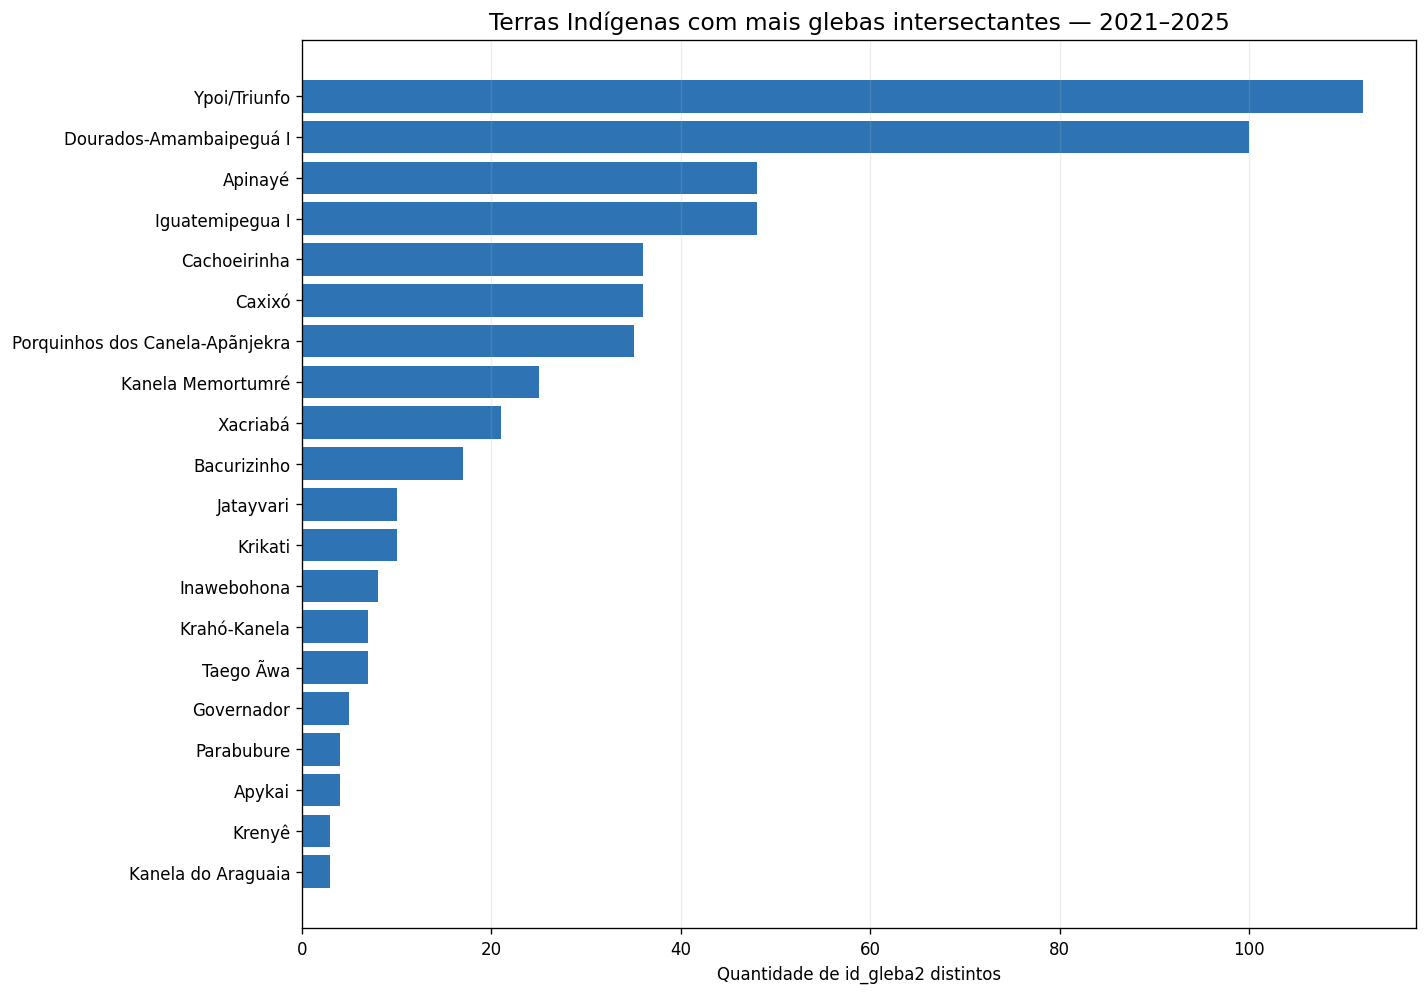

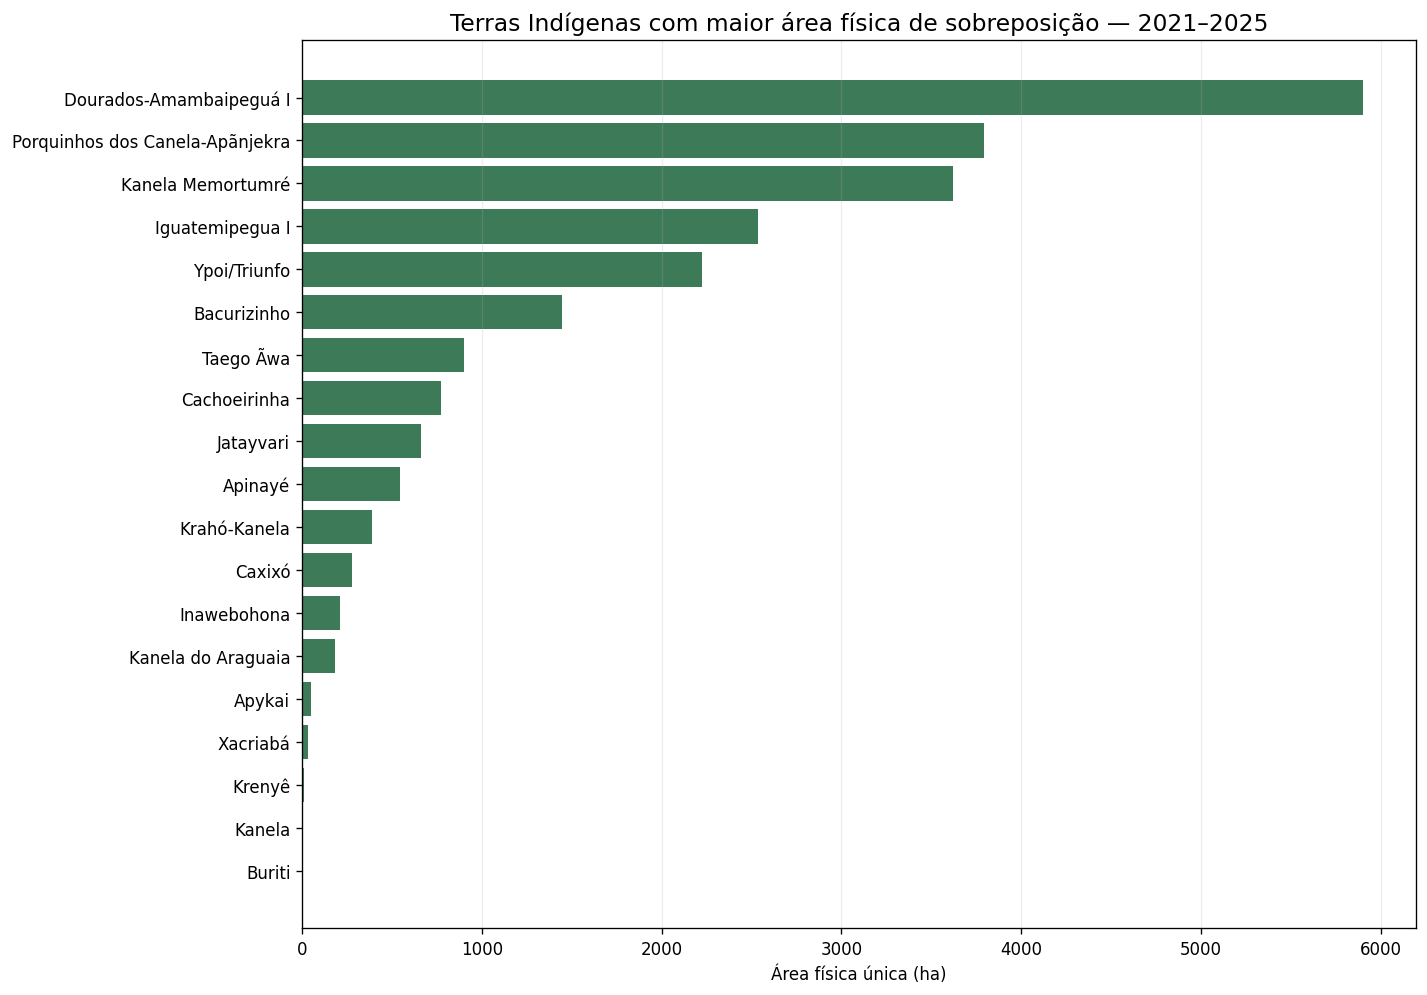

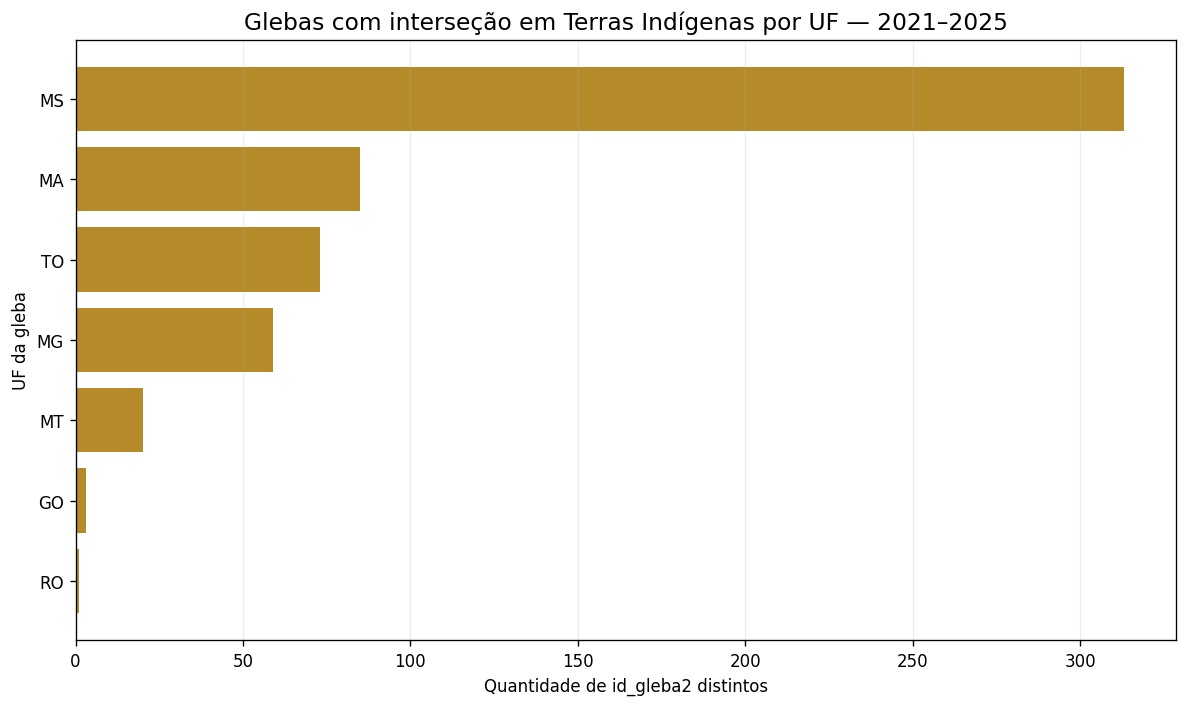

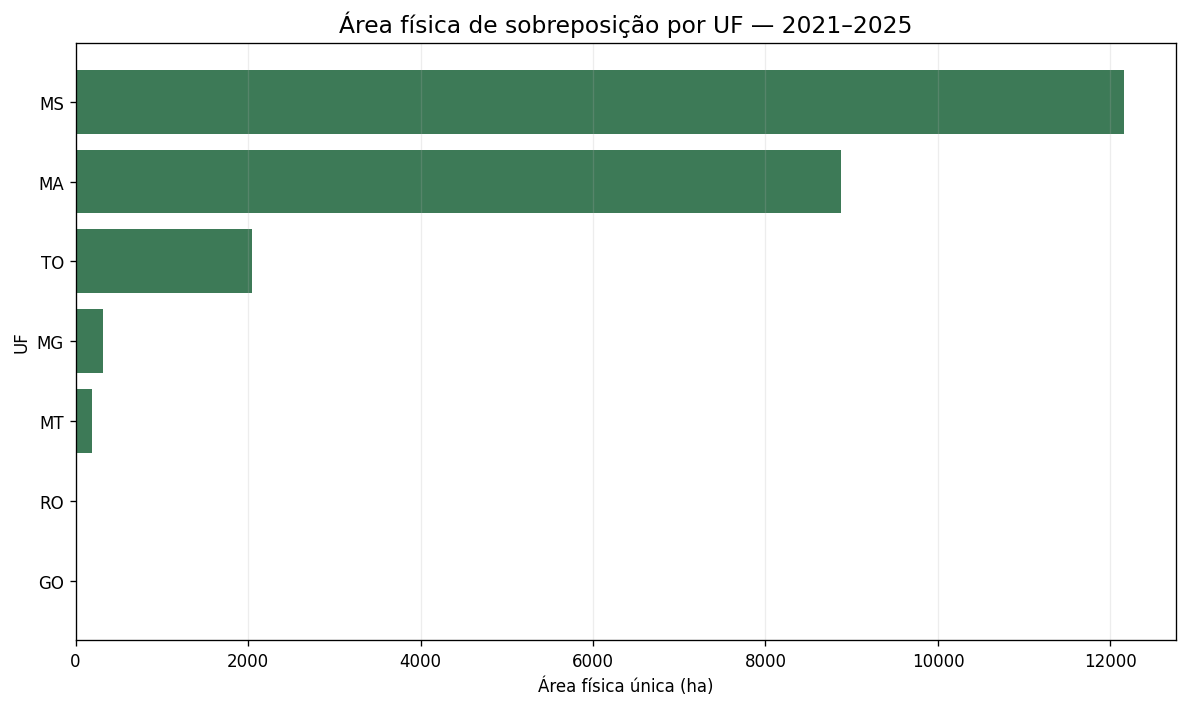

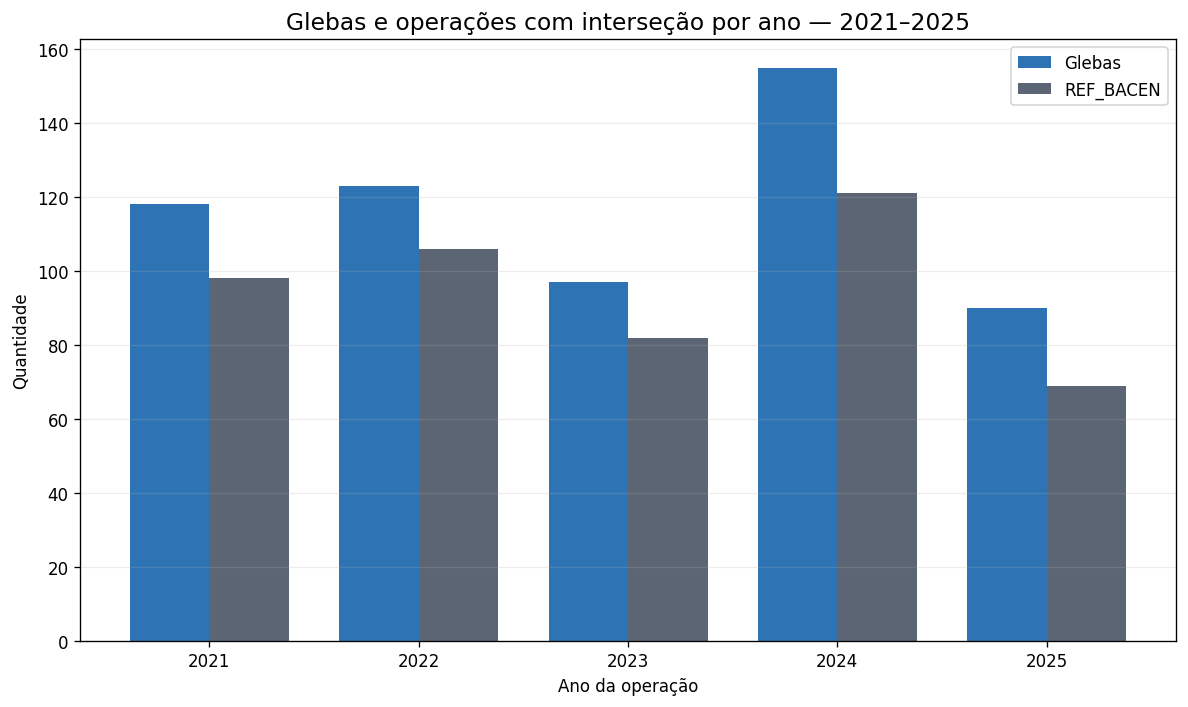

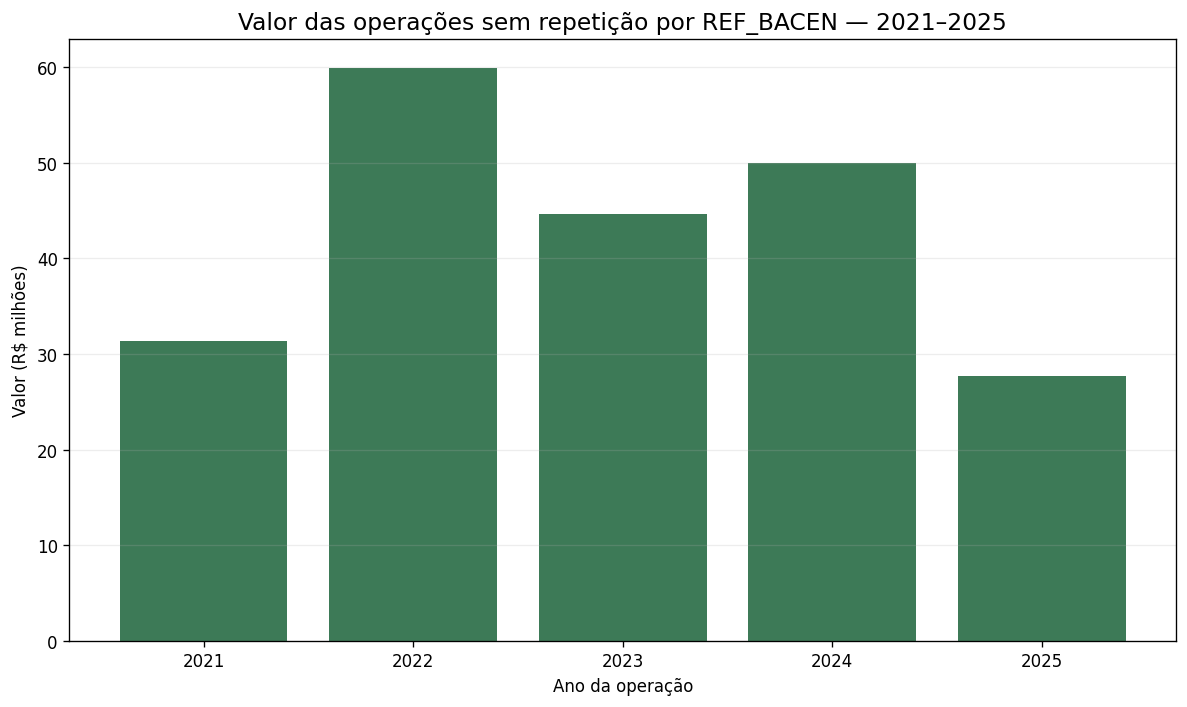

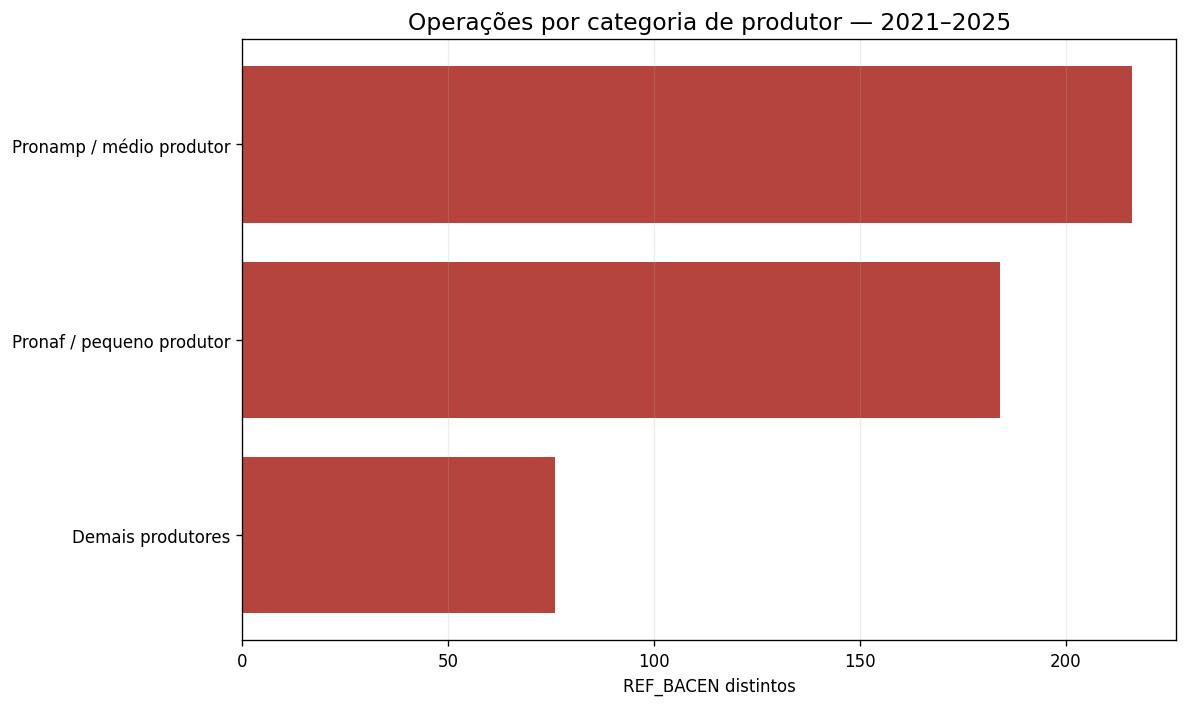

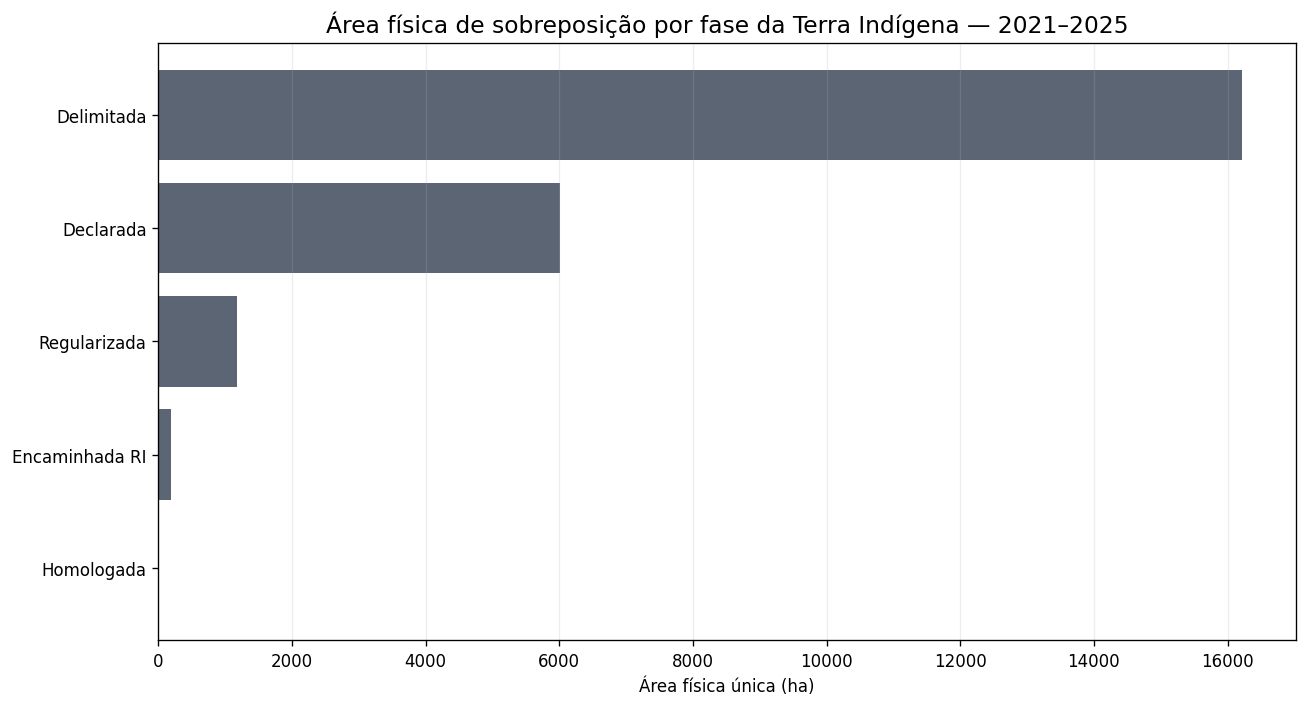

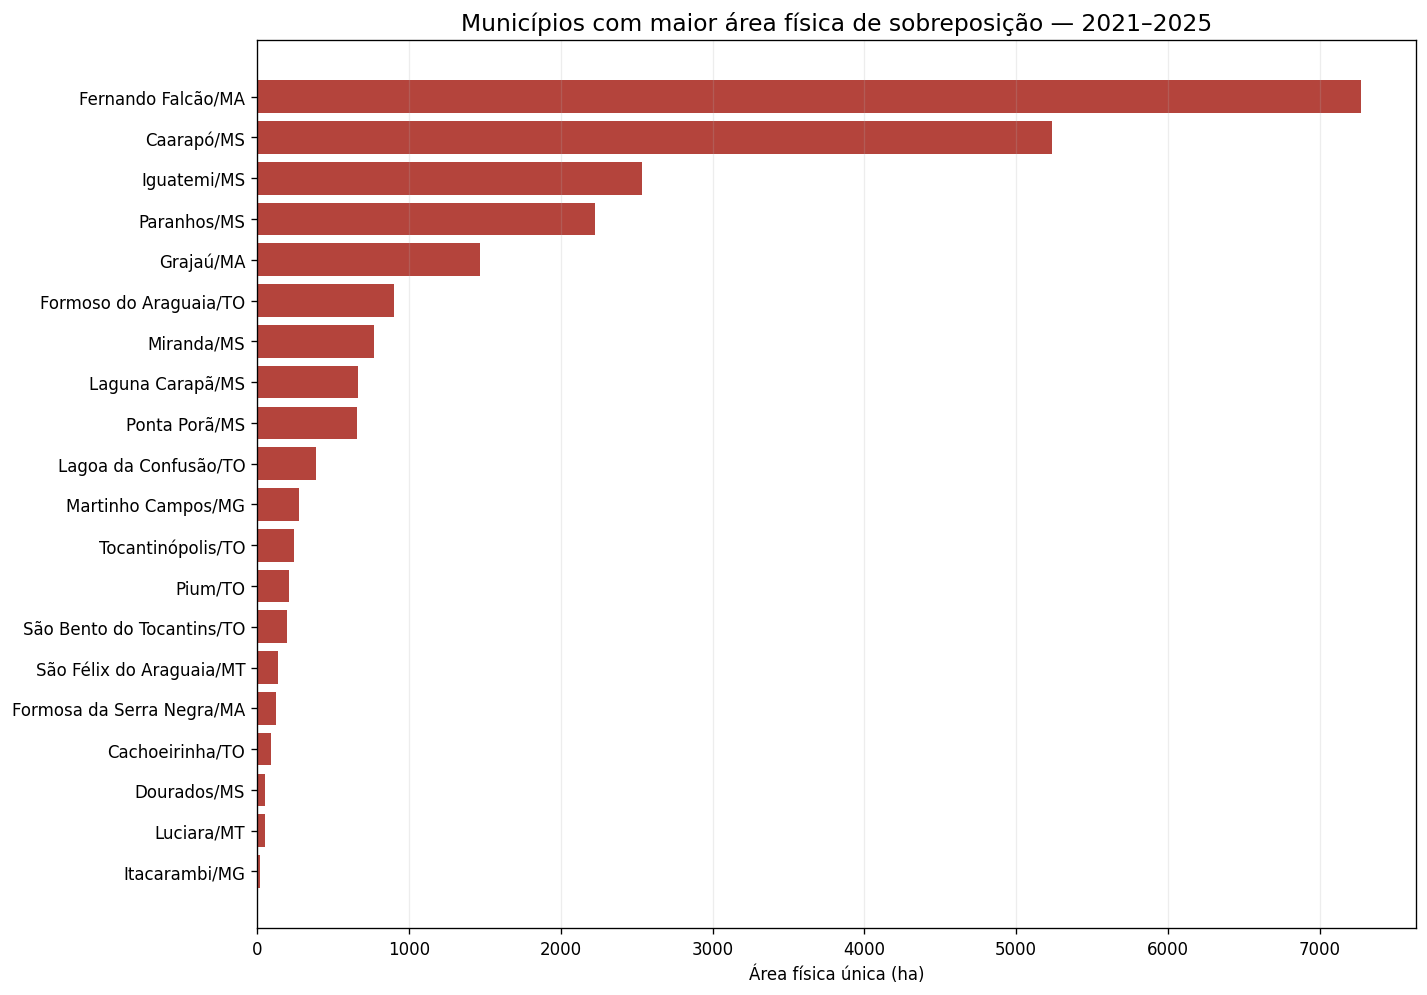

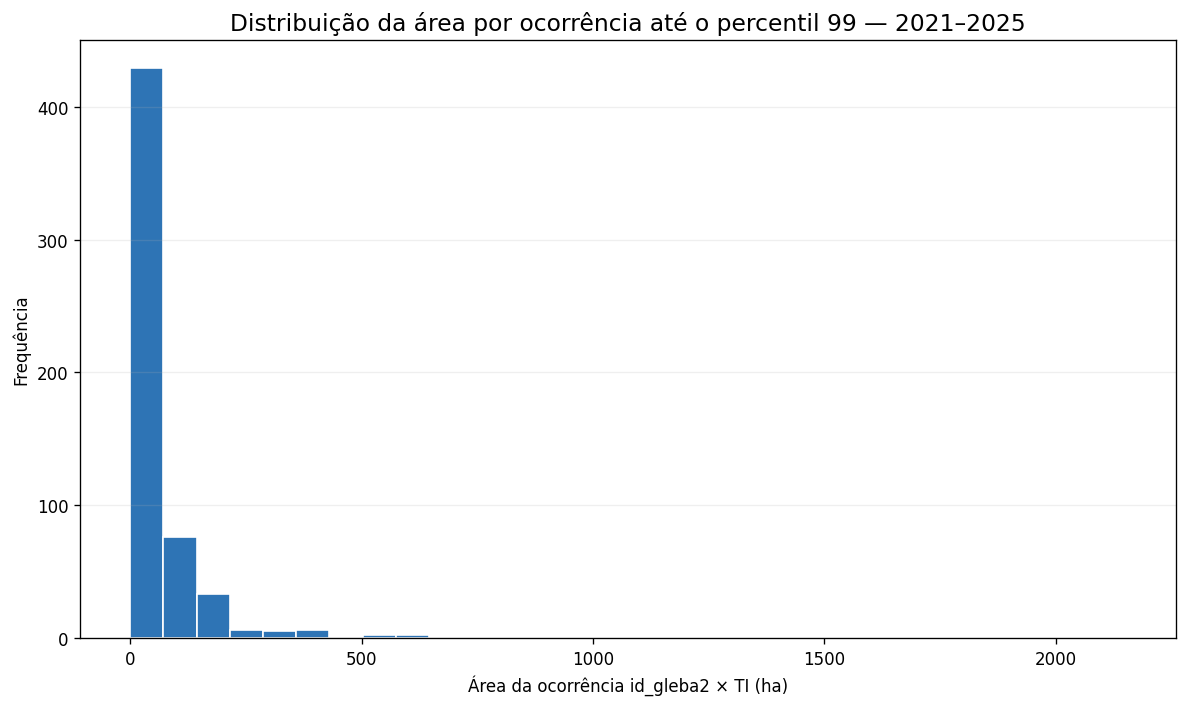

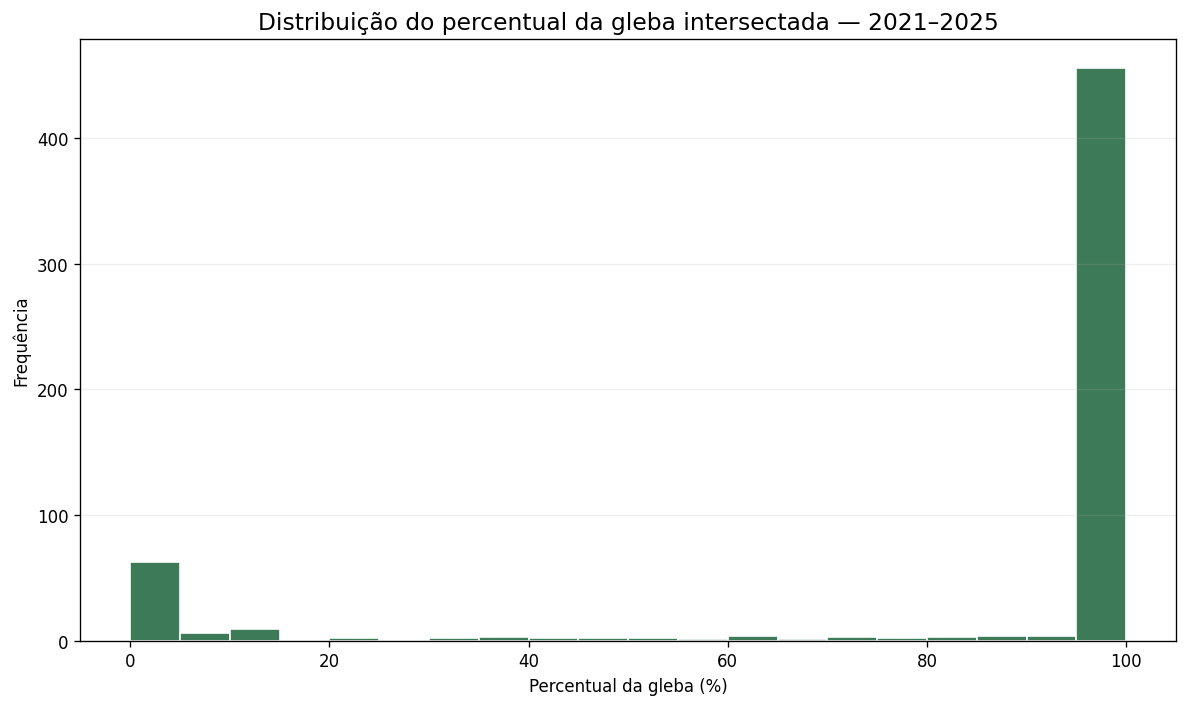

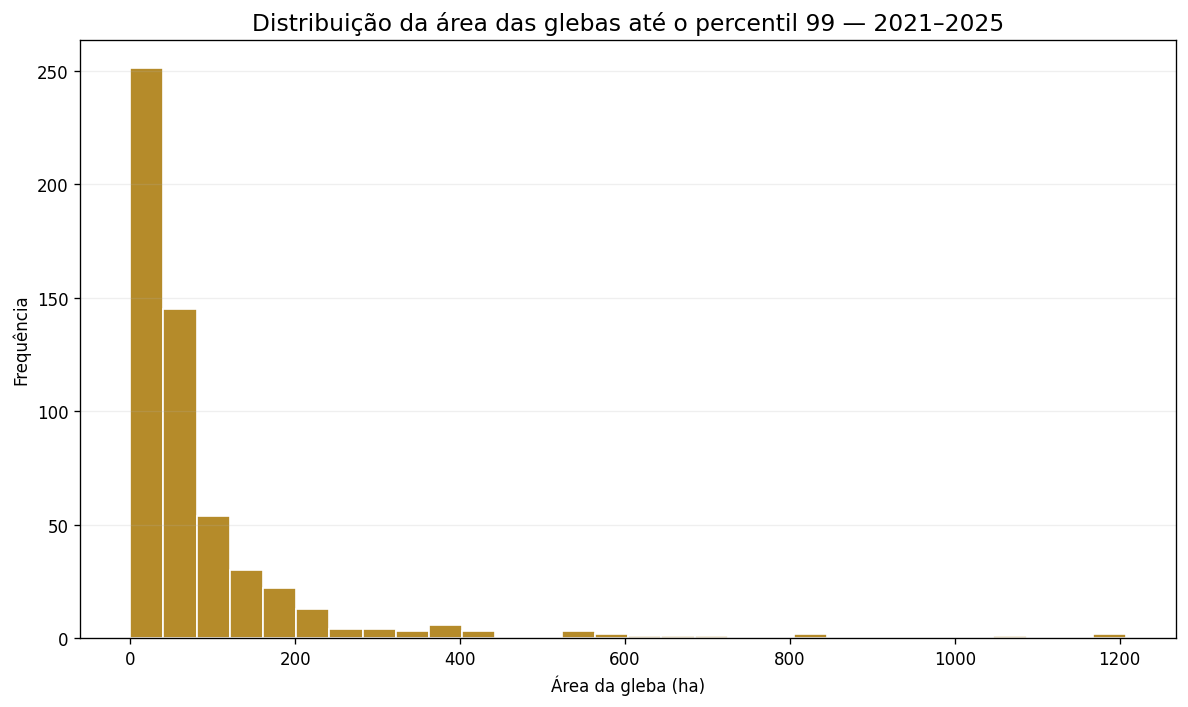

Gráficos e histogramas gerados: 12


In [11]:
# ============================================================
# 11. GERAR GRÁFICOS E HISTOGRAMAS
# ============================================================

COR_AZUL = "#2E74B5"
COR_VERDE = "#3D7A57"
COR_VERMELHO = "#B4443C"
COR_DOURADO = "#B58B2A"
COR_CINZA = "#5B6573"

graficos = OrderedDict()

def salvar_figura(chave, nome):
    caminho = PASTA_GRAFICOS / nome
    plt.tight_layout()
    plt.savefig(caminho, bbox_inches="tight", facecolor="white")
    plt.show()
    plt.close()
    graficos[chave] = caminho
    return caminho


top_ti_glebas = resumo_ti.nlargest(TOP_N, "QUANTIDADE_GLEBAS").sort_values("QUANTIDADE_GLEBAS")
plt.figure(figsize=(12, max(7, len(top_ti_glebas) * 0.42)))
plt.barh(top_ti_glebas["_TI_NOME"], top_ti_glebas["QUANTIDADE_GLEBAS"], color=COR_AZUL)
plt.title(f"Terras Indígenas com mais glebas intersectantes — {PERIODO_CURTO}")
plt.xlabel("Quantidade de id_gleba2 distintos")
plt.ylabel("")
plt.grid(axis="x", alpha=0.22)
salvar_figura("ti_glebas", "01_top_tis_por_glebas.png")

top_ti_area = resumo_ti.nlargest(TOP_N, "AREA_FISICA_UNICA_HA").sort_values("AREA_FISICA_UNICA_HA")
plt.figure(figsize=(12, max(7, len(top_ti_area) * 0.42)))
plt.barh(top_ti_area["_TI_NOME"], top_ti_area["AREA_FISICA_UNICA_HA"], color=COR_VERDE)
plt.title(f"Terras Indígenas com maior área física de sobreposição — {PERIODO_CURTO}")
plt.xlabel("Área física única (ha)")
plt.ylabel("")
plt.grid(axis="x", alpha=0.22)
salvar_figura("ti_area", "02_top_tis_por_area_fisica.png")

uf_plot = resumo_uf.sort_values("QUANTIDADE_GLEBAS")
plt.figure(figsize=(10, max(6, len(uf_plot) * 0.45)))
plt.barh(uf_plot["UF"].astype(str), uf_plot["QUANTIDADE_GLEBAS"], color=COR_DOURADO)
plt.title(f"Glebas com interseção em Terras Indígenas por UF — {PERIODO_CURTO}")
plt.xlabel("Quantidade de id_gleba2 distintos")
plt.ylabel("UF da gleba")
plt.grid(axis="x", alpha=0.22)
salvar_figura("uf_glebas", "03_glebas_por_uf.png")

uf_area_plot = resumo_uf.sort_values("AREA_FISICA_UNICA_HA")
plt.figure(figsize=(10, max(6, len(uf_area_plot) * 0.45)))
plt.barh(uf_area_plot["UF"].astype(str), uf_area_plot["AREA_FISICA_UNICA_HA"], color=COR_VERDE)
plt.title(f"Área física de sobreposição por UF — {PERIODO_CURTO}")
plt.xlabel("Área física única (ha)")
plt.ylabel("UF")
plt.grid(axis="x", alpha=0.22)
salvar_figura("uf_area", "04_area_fisica_por_uf.png")

plt.figure(figsize=(10, 6))
x = np.arange(len(resumo_ano))
largura = 0.38
plt.bar(x - largura/2, resumo_ano["QUANTIDADE_GLEBAS"], width=largura, label="Glebas", color=COR_AZUL)
plt.bar(x + largura/2, resumo_ano["QUANTIDADE_REF_BACEN"], width=largura, label="REF_BACEN", color=COR_CINZA)
plt.xticks(x, resumo_ano["_ANO"].astype("Int64").astype(str))
plt.title(f"Glebas e operações com interseção por ano — {PERIODO_CURTO}")
plt.xlabel("Ano da operação")
plt.ylabel("Quantidade")
plt.legend()
plt.grid(axis="y", alpha=0.22)
salvar_figura("ano_contagens", "05_glebas_e_operacoes_por_ano.png")

if resumo_ano["VALOR_TOTAL_R"].notna().any():
    plt.figure(figsize=(10, 6))
    plt.bar(resumo_ano["_ANO"].astype("Int64").astype(str), resumo_ano["VALOR_TOTAL_R"] / 1_000_000, color=COR_VERDE)
    plt.title(f"Valor das operações sem repetição por REF_BACEN — {PERIODO_CURTO}")
    plt.xlabel("Ano da operação")
    plt.ylabel("Valor (R$ milhões)")
    plt.grid(axis="y", alpha=0.22)
    salvar_figura("ano_valor", "06_valor_operacoes_por_ano.png")

if not resumo_produtor.empty:
    produtor_plot = resumo_produtor.sort_values("QUANTIDADE_REF_BACEN")
    plt.figure(figsize=(10, 6))
    plt.barh(produtor_plot["_TIPO_PRODUTOR"], produtor_plot["QUANTIDADE_REF_BACEN"], color=COR_VERMELHO)
    plt.title(f"Operações por categoria de produtor — {PERIODO_CURTO}")
    plt.xlabel("REF_BACEN distintos")
    plt.ylabel("")
    plt.grid(axis="x", alpha=0.22)
    salvar_figura("produtor_refs", "07_operacoes_por_tipo_produtor.png")

fase_plot = resumo_fase[resumo_fase["_TI_FASE"].ne("Não informado")].sort_values("AREA_FISICA_UNICA_HA")
if not fase_plot.empty:
    plt.figure(figsize=(11, max(6, len(fase_plot) * 0.5)))
    plt.barh(fase_plot["_TI_FASE"], fase_plot["AREA_FISICA_UNICA_HA"], color=COR_CINZA)
    plt.title(f"Área física de sobreposição por fase da Terra Indígena — {PERIODO_CURTO}")
    plt.xlabel("Área física única (ha)")
    plt.ylabel("")
    plt.grid(axis="x", alpha=0.22)
    salvar_figura("fase_area", "08_area_por_fase_ti.png")

top_municipios_plot = resumo_municipio.head(TOP_N).copy()
top_municipios_plot["MUNICIPIO_UF"] = top_municipios_plot["MUNICIPIO"] + "/" + top_municipios_plot["UF"]
top_municipios_plot = top_municipios_plot.sort_values("AREA_FISICA_UNICA_HA")
plt.figure(figsize=(12, max(7, len(top_municipios_plot) * 0.42)))
plt.barh(top_municipios_plot["MUNICIPIO_UF"], top_municipios_plot["AREA_FISICA_UNICA_HA"], color=COR_VERMELHO)
plt.title(f"Municípios com maior área física de sobreposição — {PERIODO_CURTO}")
plt.xlabel("Área física única (ha)")
plt.ylabel("")
plt.grid(axis="x", alpha=0.22)
salvar_figura("municipios_area", "09_top_municipios_por_area_fisica.png")

# Histogramas: o corte no percentil 99 é explicitado no título e na legenda do Word.
areas_intersecao = gdf_ocorrencias["_AREA_INTERSECAO_GEOM_HA"].dropna()
if not areas_intersecao.empty:
    p99_area = areas_intersecao.quantile(0.99)
    plt.figure(figsize=(10, 6))
    plt.hist(areas_intersecao[areas_intersecao <= p99_area], bins=30, color=COR_AZUL, edgecolor="white")
    plt.title(f"Distribuição da área por ocorrência até o percentil 99 — {PERIODO_CURTO}")
    plt.xlabel("Área da ocorrência id_gleba2 × TI (ha)")
    plt.ylabel("Frequência")
    plt.grid(axis="y", alpha=0.20)
    salvar_figura("hist_area_intersecao", "10_histograma_area_intersecao_p99.png")

percentuais = gdf_ocorrencias["_PERCENTUAL_GLEBA"].dropna()
if not percentuais.empty:
    plt.figure(figsize=(10, 6))
    plt.hist(percentuais.clip(0, 100), bins=np.arange(0, 105, 5), color=COR_VERDE, edgecolor="white")
    plt.title(f"Distribuição do percentual da gleba intersectada — {PERIODO_CURTO}")
    plt.xlabel("Percentual da gleba (%)")
    plt.ylabel("Frequência")
    plt.grid(axis="y", alpha=0.20)
    salvar_figura("hist_percentual", "11_histograma_percentual_gleba.png")

areas_gleba = gdf_glebas["_AREA_GLEBA_GEOM_HA"].dropna()
if not areas_gleba.empty:
    p99_gleba = areas_gleba.quantile(0.99)
    plt.figure(figsize=(10, 6))
    plt.hist(areas_gleba[areas_gleba <= p99_gleba], bins=30, color=COR_DOURADO, edgecolor="white")
    plt.title(f"Distribuição da área das glebas até o percentil 99 — {PERIODO_CURTO}")
    plt.xlabel("Área da gleba (ha)")
    plt.ylabel("Frequência")
    plt.grid(axis="y", alpha=0.20)
    salvar_figura("hist_area_gleba", "12_histograma_area_gleba_p99.png")

print("Gráficos e histogramas gerados:", len(graficos))

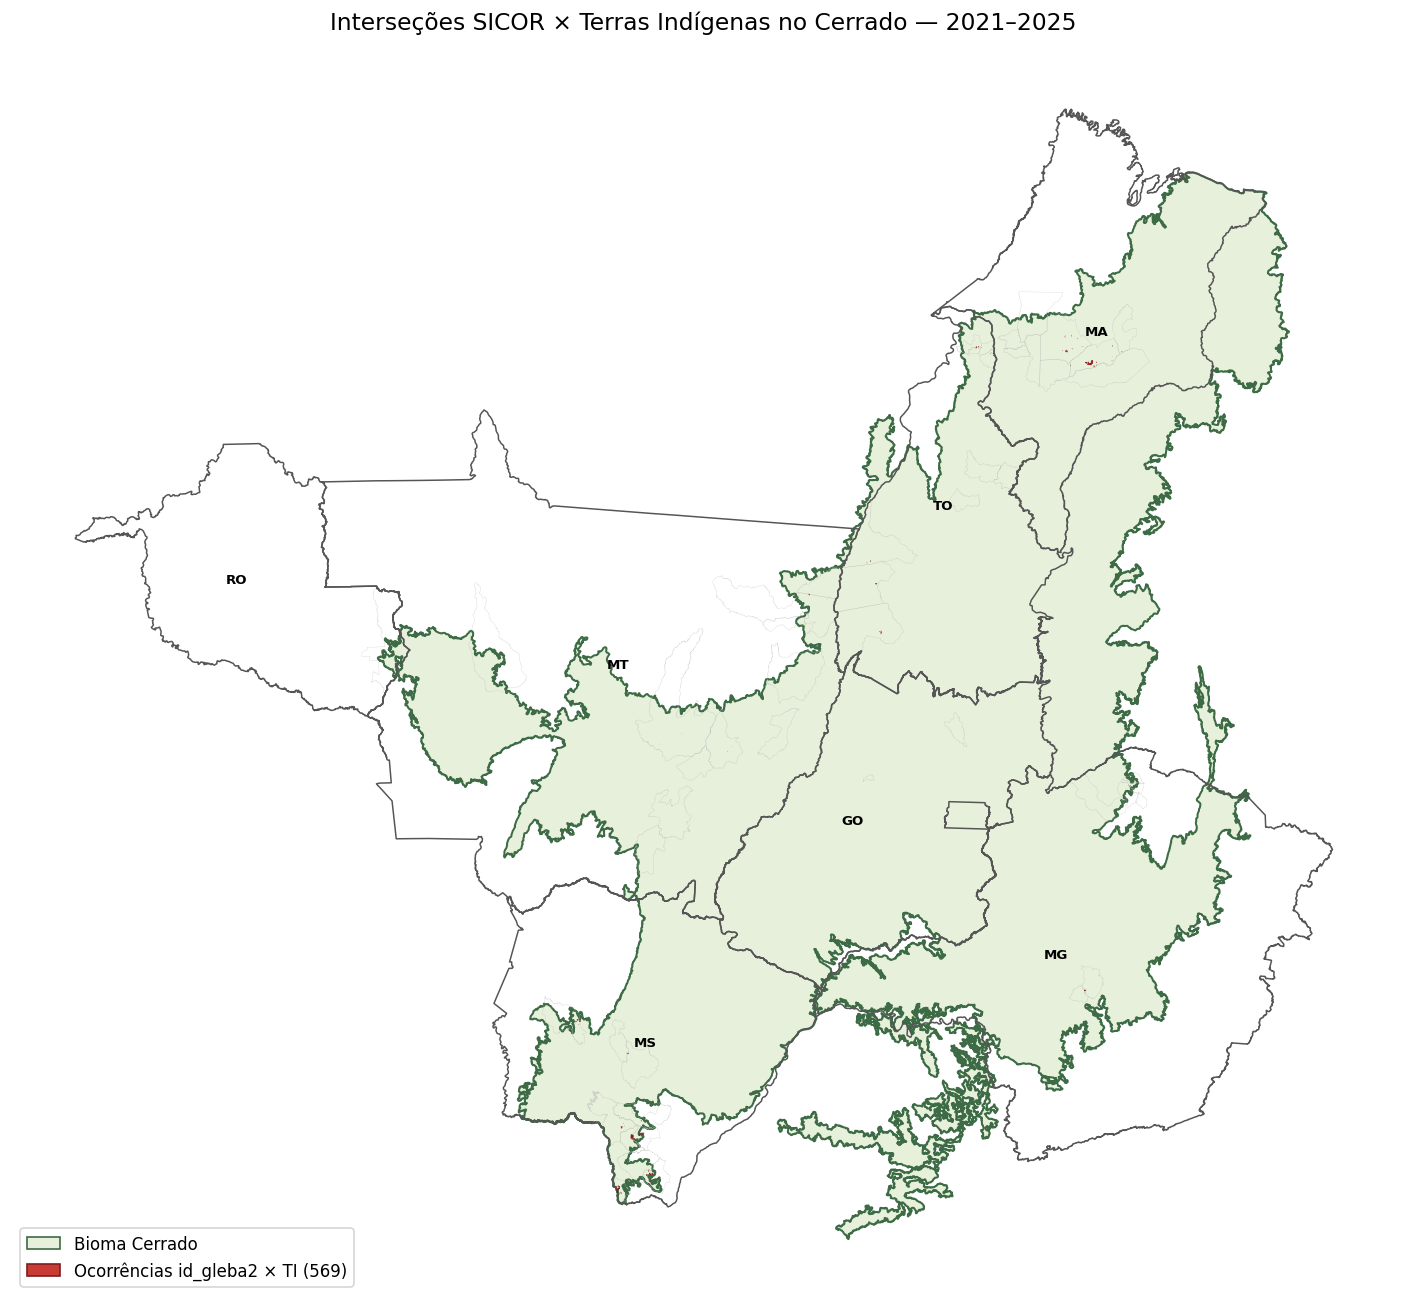

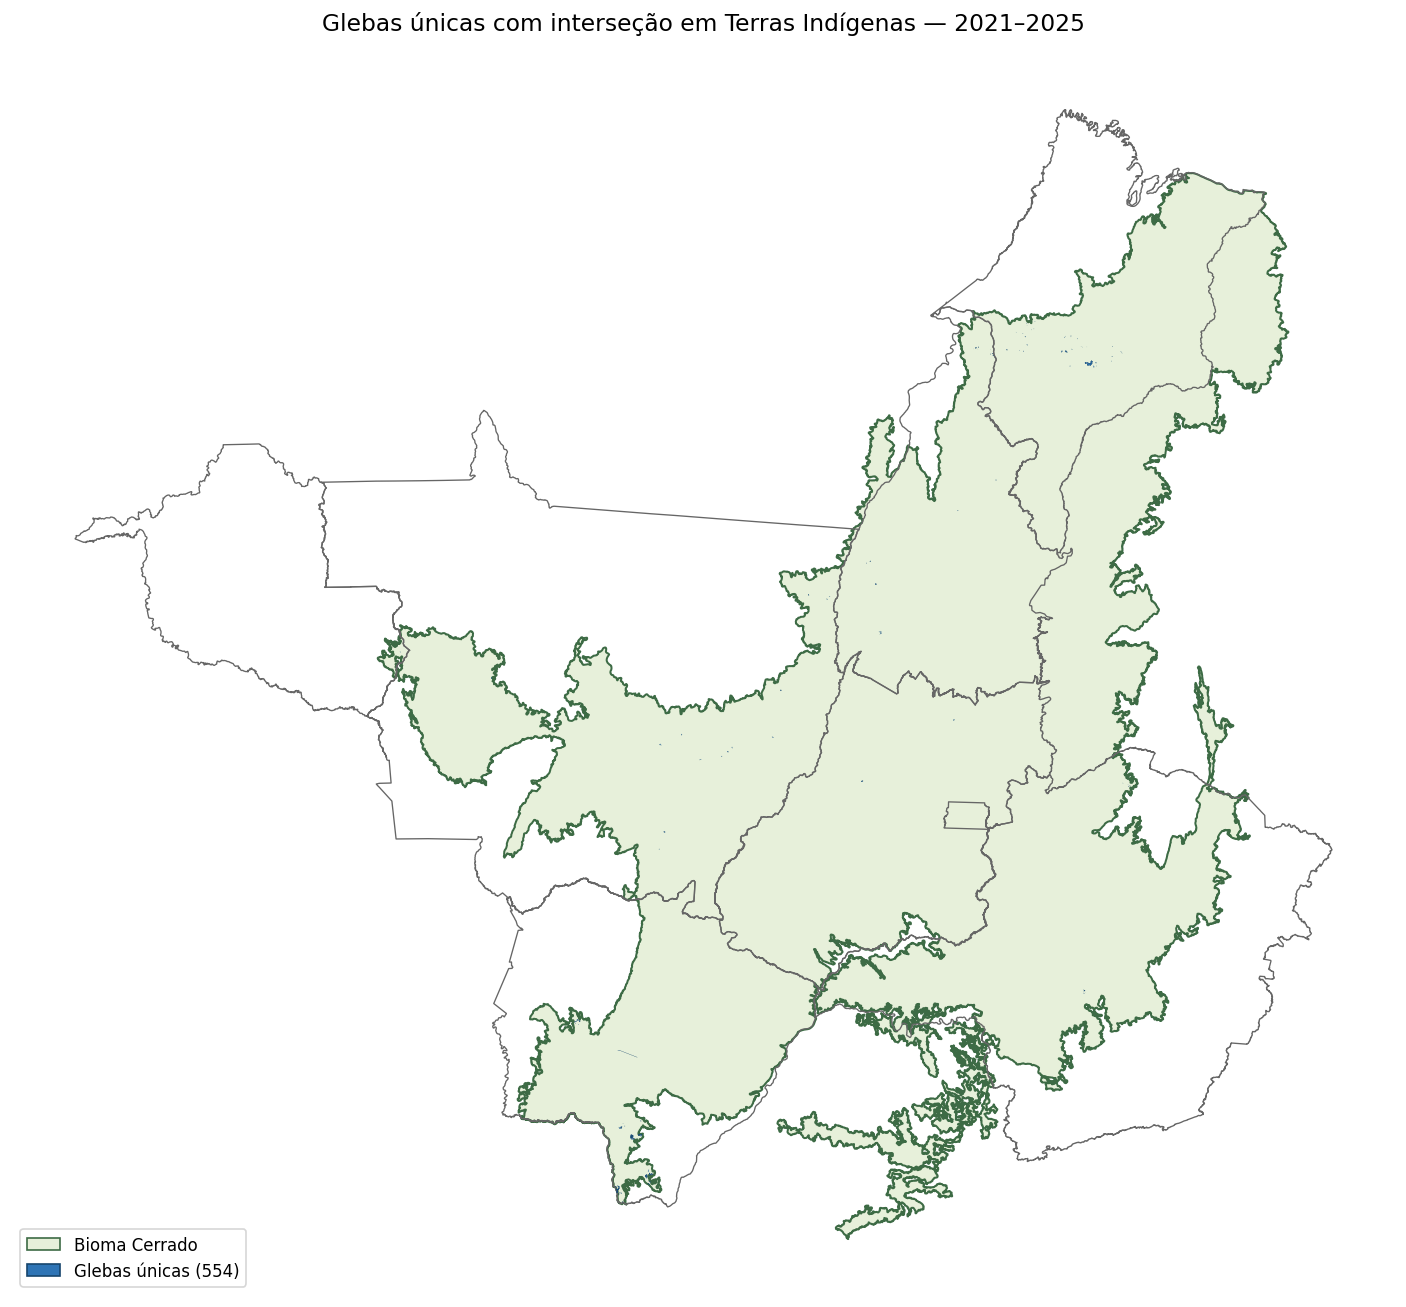

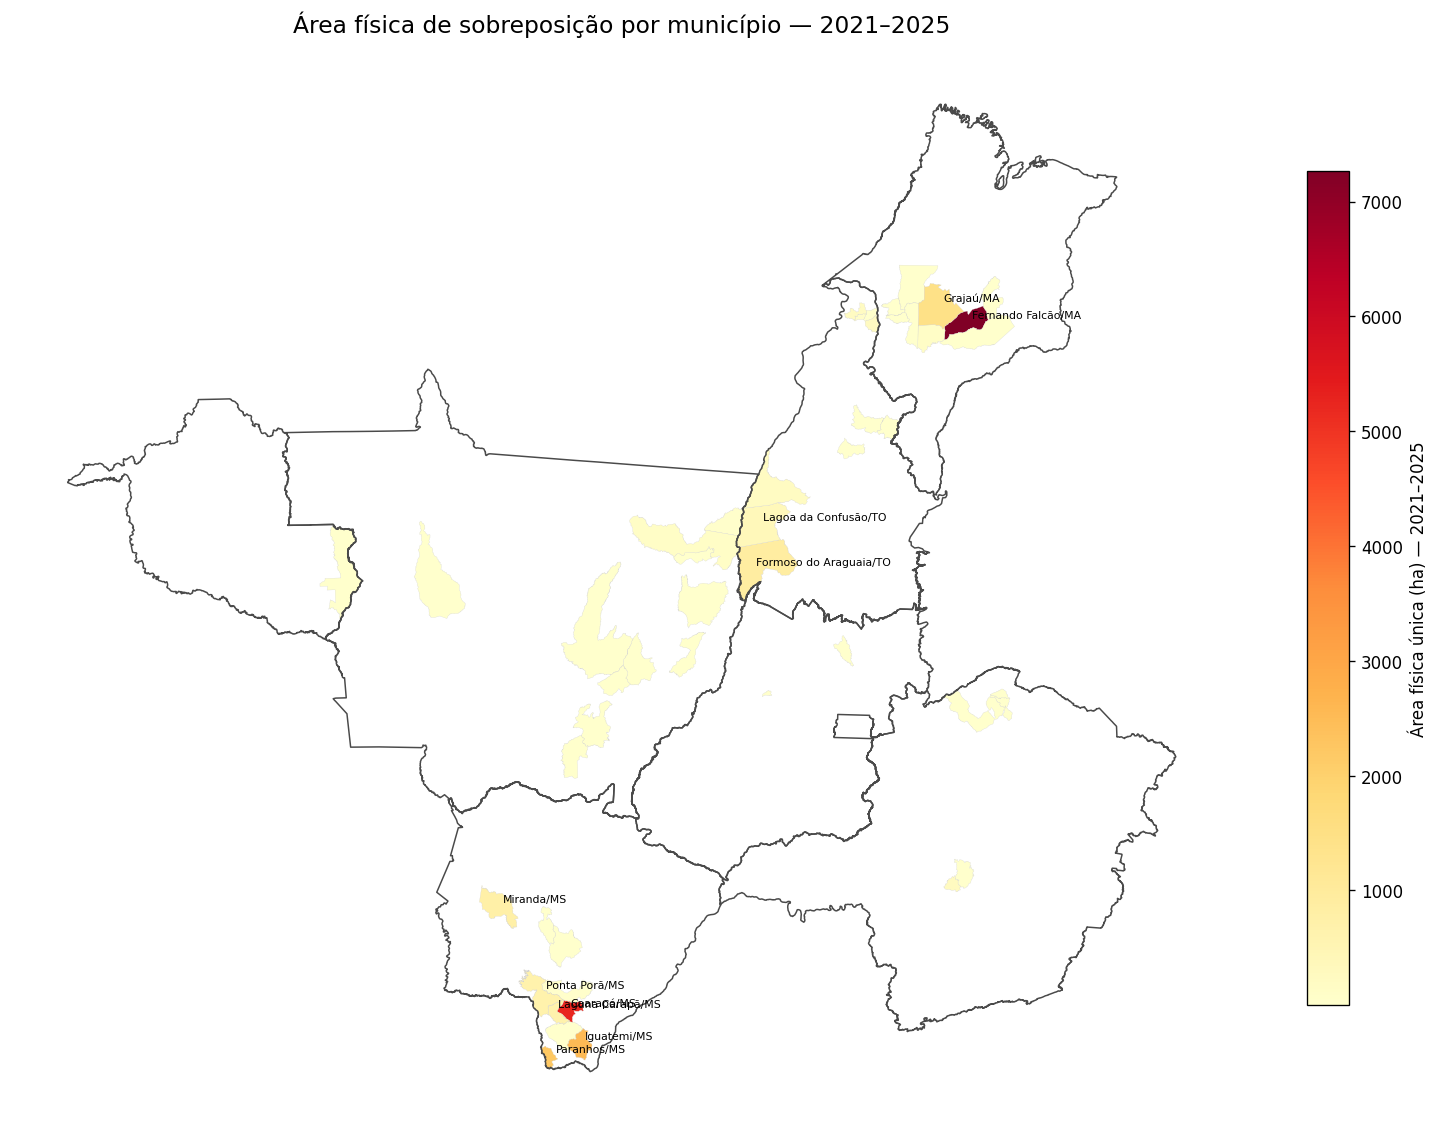

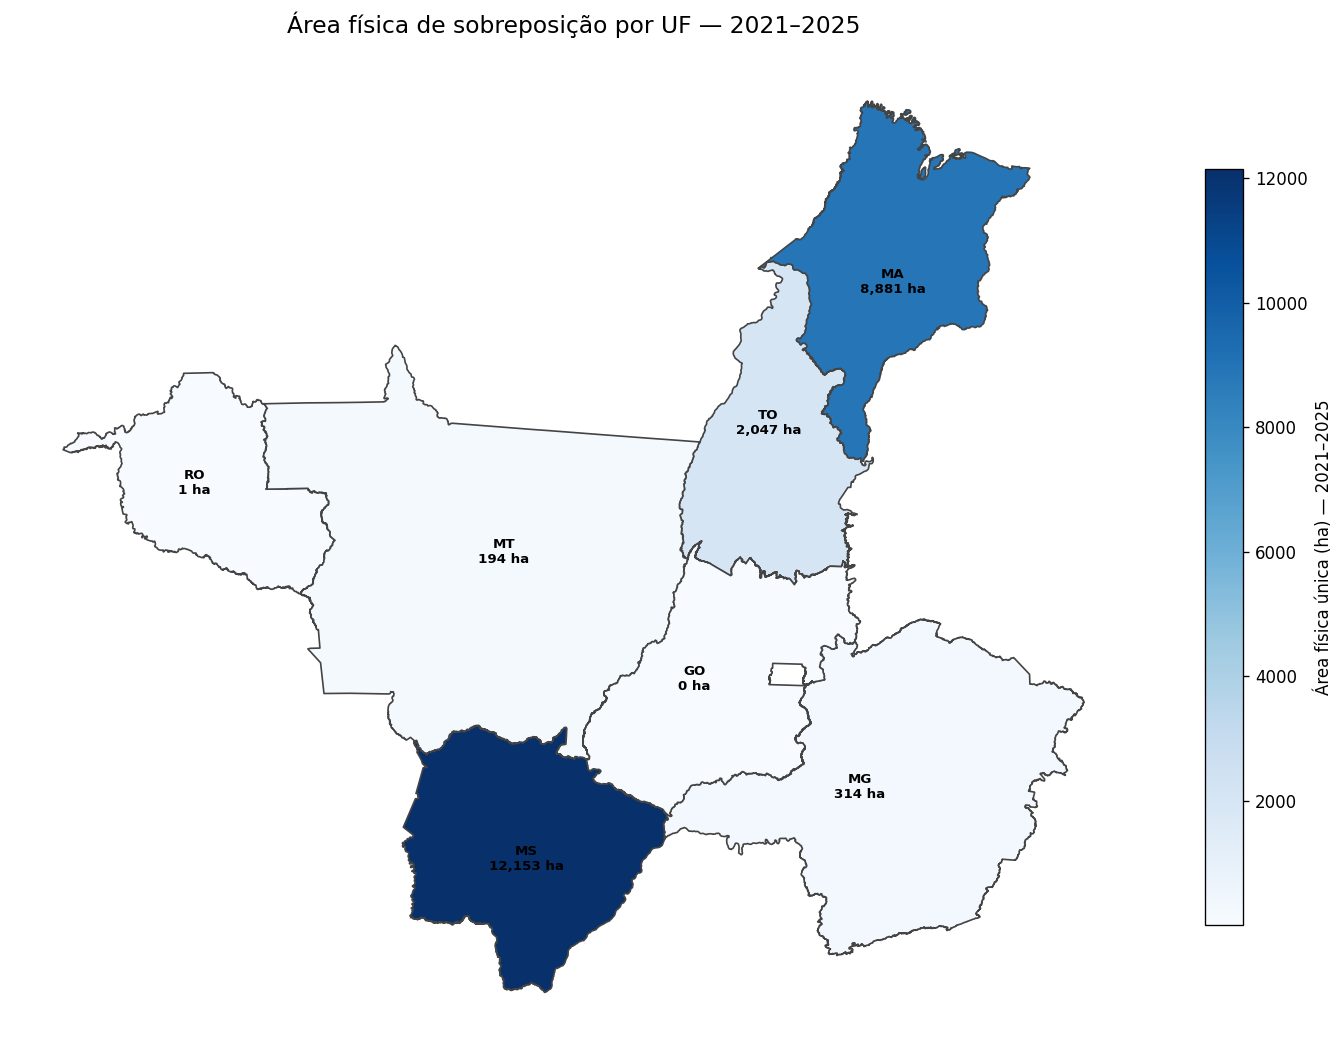

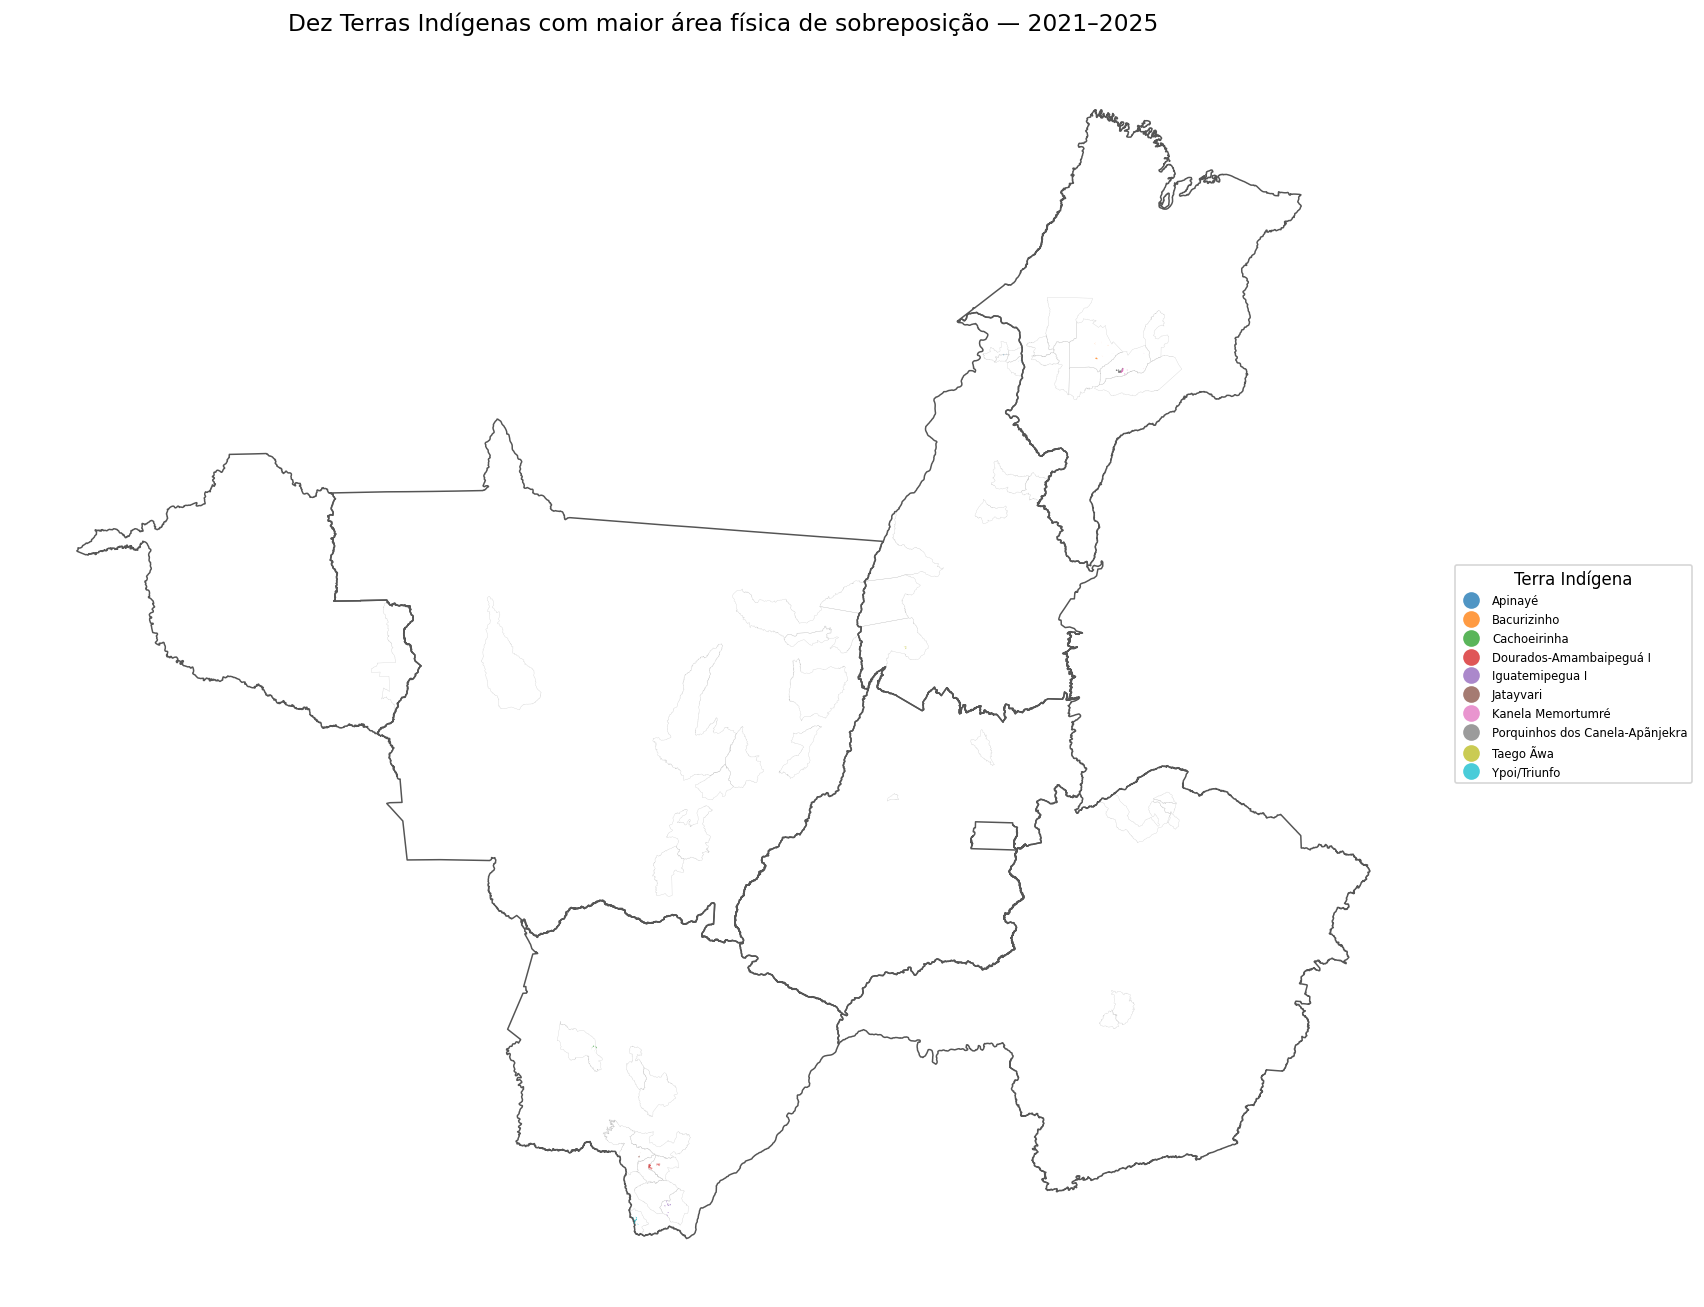

Mapas gerados: 5


In [12]:
# ============================================================
# 12. PREPARAR CAMADAS TEMÁTICAS E GERAR MAPAS
# ============================================================

mapas = OrderedDict()

def salvar_mapa(chave, nome):
    caminho = PASTA_MAPAS / nome
    plt.tight_layout()
    plt.savefig(caminho, bbox_inches="tight", facecolor="white")
    plt.show()
    plt.close()
    mapas[chave] = caminho
    return caminho


cerrado_mapa = cerrado.to_crs(CRS_AREA)
estados_mapa = estados_relevantes.to_crs(CRS_AREA)
municipios_mapa = municipios_relevantes.to_crs(CRS_AREA)
ocorrencias_mapa = gdf_ocorrencias.to_crs(CRS_AREA)
glebas_mapa = gdf_glebas.to_crs(CRS_AREA)

# 1. Mapa geral das ocorrências.
fig, ax = plt.subplots(figsize=(13, 11))
cerrado_mapa.plot(ax=ax, facecolor="#E7F0DA", edgecolor="#3D6B45", linewidth=1.2, zorder=1)
municipios_mapa.boundary.plot(ax=ax, color="#B9B9B9", linewidth=0.18, alpha=0.7, zorder=2)
estados_mapa.boundary.plot(ax=ax, color="#555555", linewidth=0.9, zorder=3)
ocorrencias_mapa.plot(ax=ax, facecolor="#C83C35", edgecolor="#7E1F1B", linewidth=0.15, alpha=0.72, rasterized=True, zorder=4)
for _, linha in estados_mapa.iterrows():
    ponto = linha.geometry.representative_point()
    ax.text(ponto.x, ponto.y, linha["UF"], fontsize=8, fontweight="bold", ha="center", va="center", zorder=5)
ax.set_title(f"Interseções SICOR × Terras Indígenas no Cerrado — {PERIODO_CURTO}", pad=14)
ax.legend(handles=[
    Patch(facecolor="#E7F0DA", edgecolor="#3D6B45", label="Bioma Cerrado"),
    Patch(facecolor="#C83C35", edgecolor="#7E1F1B", label=f"Ocorrências id_gleba2 × TI ({len(gdf_ocorrencias):,})"),
], loc="lower left")
ax.set_axis_off()
salvar_mapa("geral", "01_mapa_geral_intersecoes.png")

# 2. Mapa das glebas únicas presentes na base.
fig, ax = plt.subplots(figsize=(13, 11))
cerrado_mapa.plot(ax=ax, facecolor="#E7F0DA", edgecolor="#3D6B45", linewidth=1.2, zorder=1)
estados_mapa.boundary.plot(ax=ax, color="#666666", linewidth=0.8, zorder=2)
glebas_mapa.plot(ax=ax, facecolor="#2E74B5", edgecolor="#17466D", linewidth=0.15, alpha=0.62, rasterized=True, zorder=3)
ax.set_title(f"Glebas únicas com interseção em Terras Indígenas — {PERIODO_CURTO}", pad=14)
ax.legend(handles=[
    Patch(facecolor="#E7F0DA", edgecolor="#3D6B45", label="Bioma Cerrado"),
    Patch(facecolor="#2E74B5", edgecolor="#17466D", label=f"Glebas únicas ({total_glebas:,})"),
], loc="lower left")
ax.set_axis_off()
salvar_mapa("glebas", "02_mapa_glebas_unicas.png")

# Camadas municipais e estaduais com área física única.
municipios_tema = municipios_relevantes.merge(
    resumo_municipio[["COD_MUNICIPIO", "AREA_FISICA_UNICA_HA"]],
    on="COD_MUNICIPIO", how="left", validate="one_to_one",
)
municipios_tema["AREA_FISICA_UNICA_HA"] = municipios_tema["AREA_FISICA_UNICA_HA"].fillna(0)

estados_tema = estados_relevantes.merge(
    resumo_uf[["UF", "AREA_FISICA_UNICA_HA"]],
    on="UF", how="left", validate="one_to_one",
)
estados_tema["AREA_FISICA_UNICA_HA"] = estados_tema["AREA_FISICA_UNICA_HA"].fillna(0)

fig, ax = plt.subplots(figsize=(13, 11))
municipios_tema.to_crs(CRS_AREA).plot(
    ax=ax, column="AREA_FISICA_UNICA_HA", cmap="YlOrRd", legend=True,
    linewidth=0.15, edgecolor="#D0D0D0",
    legend_kwds={"label": f"Área física única (ha) — {PERIODO_CURTO}", "shrink": 0.65},
)
estados_mapa.boundary.plot(ax=ax, color="#4A4A4A", linewidth=0.9, zorder=3)
for _, linha in resumo_municipio.head(10).iterrows():
    feicao = municipios_tema[municipios_tema["COD_MUNICIPIO"].eq(linha["COD_MUNICIPIO"])].to_crs(CRS_AREA)
    if not feicao.empty:
        ponto = feicao.geometry.iloc[0].representative_point()
        ax.annotate(f"{linha['MUNICIPIO']}/{linha['UF']}", (ponto.x, ponto.y), xytext=(3, 3), textcoords="offset points", fontsize=6.5)
ax.set_title(f"Área física de sobreposição por município — {PERIODO_CURTO}", pad=14)
ax.set_axis_off()
salvar_mapa("municipios", "03_mapa_area_por_municipio.png")

fig, ax = plt.subplots(figsize=(12, 10))
estados_tema.to_crs(CRS_AREA).plot(
    ax=ax, column="AREA_FISICA_UNICA_HA", cmap="Blues", legend=True,
    linewidth=1.0, edgecolor="#444444",
    legend_kwds={"label": f"Área física única (ha) — {PERIODO_CURTO}", "shrink": 0.65},
)
for _, linha in estados_tema.to_crs(CRS_AREA).iterrows():
    ponto = linha.geometry.representative_point()
    ax.text(ponto.x, ponto.y, f"{linha['UF']}\n{linha['AREA_FISICA_UNICA_HA']:,.0f} ha", ha="center", va="center", fontsize=8, fontweight="bold")
ax.set_title(f"Área física de sobreposição por UF — {PERIODO_CURTO}", pad=14)
ax.set_axis_off()
salvar_mapa("ufs", "04_mapa_area_por_uf.png")

# 5. Localização das dez TIs com maior área física de sobreposição.
top_ids = resumo_ti.head(TOP_MAPA)["_TI_ID"].tolist()
top_mapa = gdf_ocorrencias[gdf_ocorrencias["_TI_ID"].isin(top_ids)].to_crs(CRS_AREA)
fig, ax = plt.subplots(figsize=(14, 11))
municipios_mapa.boundary.plot(ax=ax, color="#C5C5C5", linewidth=0.16, zorder=1)
estados_mapa.boundary.plot(ax=ax, color="#555555", linewidth=0.9, zorder=2)
top_mapa.plot(
    ax=ax, column="_TI_NOME", categorical=True, legend=True,
    alpha=0.78, linewidth=0.15, zorder=3,
    legend_kwds={"title": "Terra Indígena", "loc": "center left", "bbox_to_anchor": (1.01, 0.5), "fontsize": 7},
)
ax.set_title(f"Dez Terras Indígenas com maior área física de sobreposição — {PERIODO_CURTO}", pad=14)
ax.set_axis_off()
salvar_mapa("top_tis", "05_mapa_top_terras_indigenas.png")

print("Mapas gerados:", len(mapas))

In [13]:
# ============================================================
# 13. FUNÇÕES DE FORMATAÇÃO DO WORD
# ============================================================

AZUL = "2E74B5"
AZUL_ESCURO = "1F4D78"
CINZA_CLARO = "F2F4F7"
CINZA_TEXTO = "59636E"

def br_inteiro(valor):
    if pd.isna(valor): return "-"
    return f"{int(round(float(valor))):,}".replace(",", ".")

def br_decimal(valor, casas=2):
    if pd.isna(valor): return "-"
    texto = f"{float(valor):,.{casas}f}"
    return texto.replace(",", "X").replace(".", ",").replace("X", ".")

def br_moeda(valor):
    return "-" if pd.isna(valor) else f"R$ {br_decimal(valor, 2)}"

def br_percentual(valor):
    return "-" if pd.isna(valor) else f"{br_decimal(valor, 2)}%"

def br_generico(valor):
    if pd.isna(valor): return "-"
    if isinstance(valor, (int, np.integer)): return br_inteiro(valor)
    if isinstance(valor, (float, np.floating)): return br_decimal(valor, 2)
    return str(valor)

def definir_fonte_run(run, nome="Calibri", tamanho=11, cor=None, negrito=None, italico=None):
    run.font.name = nome
    run._element.get_or_add_rPr().rFonts.set(qn("w:ascii"), nome)
    run._element.get_or_add_rPr().rFonts.set(qn("w:hAnsi"), nome)
    run.font.size = Pt(tamanho)
    if cor: run.font.color.rgb = RGBColor.from_string(cor)
    if negrito is not None: run.bold = negrito
    if italico is not None: run.italic = italico

def sombrear_celula(celula, preenchimento):
    tc_pr = celula._tc.get_or_add_tcPr()
    shd = tc_pr.find(qn("w:shd"))
    if shd is None:
        shd = OxmlElement("w:shd")
        tc_pr.append(shd)
    shd.set(qn("w:fill"), preenchimento)

def margens_celula(celula, top=80, start=120, bottom=80, end=120):
    tc_pr = celula._tc.get_or_add_tcPr()
    tc_mar = tc_pr.first_child_found_in("w:tcMar")
    if tc_mar is None:
        tc_mar = OxmlElement("w:tcMar")
        tc_pr.append(tc_mar)
    for lado, valor in [("top", top), ("start", start), ("bottom", bottom), ("end", end)]:
        elemento = tc_mar.find(qn(f"w:{lado}"))
        if elemento is None:
            elemento = OxmlElement(f"w:{lado}")
            tc_mar.append(elemento)
        elemento.set(qn("w:w"), str(valor))
        elemento.set(qn("w:type"), "dxa")

def repetir_cabecalho(linha):
    tr_pr = linha._tr.get_or_add_trPr()
    elemento = OxmlElement("w:tblHeader")
    elemento.set(qn("w:val"), "true")
    tr_pr.append(elemento)

def definir_larguras_tabela(tabela, larguras_dxa):
    total = sum(larguras_dxa)
    tabela.autofit = False
    tbl_pr = tabela._tbl.tblPr
    tbl_w = tbl_pr.find(qn("w:tblW"))
    if tbl_w is None:
        tbl_w = OxmlElement("w:tblW")
        tbl_pr.append(tbl_w)
    tbl_w.set(qn("w:w"), str(total))
    tbl_w.set(qn("w:type"), "dxa")
    tbl_ind = tbl_pr.find(qn("w:tblInd"))
    if tbl_ind is None:
        tbl_ind = OxmlElement("w:tblInd")
        tbl_pr.append(tbl_ind)
    tbl_ind.set(qn("w:w"), "120")
    tbl_ind.set(qn("w:type"), "dxa")
    grid = tabela._tbl.tblGrid
    for filho in list(grid):
        grid.remove(filho)
    for largura in larguras_dxa:
        col = OxmlElement("w:gridCol")
        col.set(qn("w:w"), str(largura))
        grid.append(col)
    for linha in tabela.rows:
        for celula, largura in zip(linha.cells, larguras_dxa):
            tc_w = celula._tc.get_or_add_tcPr().find(qn("w:tcW"))
            if tc_w is None:
                tc_w = OxmlElement("w:tcW")
                celula._tc.get_or_add_tcPr().append(tc_w)
            tc_w.set(qn("w:w"), str(largura))
            tc_w.set(qn("w:type"), "dxa")
            margens_celula(celula)

def adicionar_legenda_tabela(doc, numero, titulo):
    p = doc.add_paragraph()
    p.paragraph_format.space_before = Pt(8)
    p.paragraph_format.space_after = Pt(4)
    p.paragraph_format.keep_with_next = True
    r = p.add_run(f"Tabela {numero} - {titulo} ({PERIODO_CURTO})")
    definir_fonte_run(r, tamanho=9, negrito=True)

def adicionar_fonte(doc, texto):
    p = doc.add_paragraph()
    p.paragraph_format.space_before = Pt(4)
    p.paragraph_format.space_after = Pt(6)
    r = p.add_run(f"Fonte: {texto}")
    definir_fonte_run(r, tamanho=8, cor=CINZA_TEXTO)

def adicionar_tabela(doc, df, colunas, titulos, larguras, formatadores=None, max_linhas=None):
    formatadores = formatadores or {}
    tabela_df = df.head(max_linhas) if max_linhas else df
    tabela = doc.add_table(rows=1, cols=len(colunas))
    tabela.style = "Table Grid"
    tabela.alignment = WD_TABLE_ALIGNMENT.CENTER
    repetir_cabecalho(tabela.rows[0])
    for i, titulo in enumerate(titulos):
        celula = tabela.rows[0].cells[i]
        celula.text = titulo
        celula.vertical_alignment = WD_CELL_VERTICAL_ALIGNMENT.CENTER
        sombrear_celula(celula, CINZA_CLARO)
        for p in celula.paragraphs:
            p.alignment = WD_ALIGN_PARAGRAPH.CENTER
            p.paragraph_format.space_after = Pt(0)
            for r in p.runs:
                definir_fonte_run(r, tamanho=8, negrito=True)
    for _, linha in tabela_df.iterrows():
        celulas = tabela.add_row().cells
        for i, coluna in enumerate(colunas):
            valor = linha.get(coluna, pd.NA)
            celulas[i].text = formatadores.get(coluna, br_generico)(valor)
            celulas[i].vertical_alignment = WD_CELL_VERTICAL_ALIGNMENT.CENTER
            for p in celulas[i].paragraphs:
                p.alignment = WD_ALIGN_PARAGRAPH.RIGHT if isinstance(valor, (int, float, np.integer, np.floating)) else WD_ALIGN_PARAGRAPH.LEFT
                p.paragraph_format.space_after = Pt(0)
                p.paragraph_format.line_spacing = 1.0
                for r in p.runs:
                    definir_fonte_run(r, tamanho=7.5)
    definir_larguras_tabela(tabela, larguras)
    return tabela

def adicionar_figura(doc, caminho, numero, titulo, nota=None, largura=6.35):
    caminho = Path(caminho)
    if not caminho.exists(): return
    p_img = doc.add_paragraph()
    p_img.alignment = WD_ALIGN_PARAGRAPH.CENTER
    p_img.paragraph_format.keep_with_next = True
    p_img.add_run().add_picture(str(caminho), width=Inches(largura))
    p = doc.add_paragraph()
    p.alignment = WD_ALIGN_PARAGRAPH.CENTER
    p.paragraph_format.space_before = Pt(2)
    p.paragraph_format.space_after = Pt(2)
    r = p.add_run(f"Figura {numero} - {titulo} ({PERIODO_CURTO})")
    definir_fonte_run(r, tamanho=9, italico=True)
    if nota:
        n = doc.add_paragraph()
        n.alignment = WD_ALIGN_PARAGRAPH.CENTER
        n.paragraph_format.space_after = Pt(2)
        rn = n.add_run(f"Nota: {nota}")
        definir_fonte_run(rn, tamanho=8, cor=CINZA_TEXTO)
    adicionar_fonte(doc, "elaboração própria a partir da base de interseção SICOR × Terras Indígenas.")

def adicionar_paragrafo(doc, texto):
    p = doc.add_paragraph()
    p.alignment = WD_ALIGN_PARAGRAPH.JUSTIFY
    p.paragraph_format.space_after = Pt(6)
    p.paragraph_format.line_spacing = 1.10
    r = p.add_run(texto)
    definir_fonte_run(r, tamanho=11)
    return p

def adicionar_numero_pagina(paragrafo):
    paragrafo.alignment = WD_ALIGN_PARAGRAPH.RIGHT
    run = paragrafo.add_run("Página ")
    definir_fonte_run(run, tamanho=8, cor=CINZA_TEXTO)
    fld = OxmlElement("w:fldSimple")
    fld.set(qn("w:instr"), "PAGE")
    paragrafo._p.append(fld)

In [14]:
# ============================================================
# 14. GERAR O RELATÓRIO WORD UNIFICADO
# ============================================================

doc = Document()
secao = doc.sections[0]
secao.page_width = Inches(8.5)
secao.page_height = Inches(11)
secao.top_margin = Inches(1)
secao.bottom_margin = Inches(1)
secao.left_margin = Inches(1)
secao.right_margin = Inches(1)
secao.header_distance = Inches(0.492)
secao.footer_distance = Inches(0.492)

# Preset visual: standard_business_brief.
normal = doc.styles["Normal"]
normal.font.name = "Calibri"
normal._element.rPr.rFonts.set(qn("w:ascii"), "Calibri")
normal._element.rPr.rFonts.set(qn("w:hAnsi"), "Calibri")
normal.font.size = Pt(11)
normal.paragraph_format.space_after = Pt(6)
normal.paragraph_format.line_spacing = 1.10

for nome, tamanho, cor, antes, depois in [
    ("Heading 1", 16, AZUL, 16, 8),
    ("Heading 2", 13, AZUL, 12, 6),
    ("Heading 3", 12, AZUL_ESCURO, 8, 4),
]:
    estilo = doc.styles[nome]
    estilo.font.name = "Calibri"
    estilo._element.rPr.rFonts.set(qn("w:ascii"), "Calibri")
    estilo._element.rPr.rFonts.set(qn("w:hAnsi"), "Calibri")
    estilo.font.size = Pt(tamanho)
    estilo.font.color.rgb = RGBColor.from_string(cor)
    estilo.font.bold = True
    estilo.paragraph_format.space_before = Pt(antes)
    estilo.paragraph_format.space_after = Pt(depois)
    estilo.paragraph_format.keep_with_next = True

# Cabeçalho e rodapé.
cabecalho = secao.header.paragraphs[0]
cabecalho.alignment = WD_ALIGN_PARAGRAPH.LEFT
r = cabecalho.add_run(f"SICOR Cerrado × Terras Indígenas | análise por id_gleba2 | {PERIODO_CURTO}")
definir_fonte_run(r, tamanho=8, cor=CINZA_TEXTO)
adicionar_numero_pagina(secao.footer.paragraphs[0])

# Abertura.
p = doc.add_paragraph()
p.paragraph_format.space_before = Pt(20)
p.paragraph_format.space_after = Pt(4)
r = p.add_run("RELATÓRIO UNIFICADO DE RESULTADOS")
definir_fonte_run(r, tamanho=23, cor="000000", negrito=True)

p = doc.add_paragraph()
p.paragraph_format.space_after = Pt(6)
r = p.add_run("Interseções entre glebas do SICOR e Terras Indígenas no bioma Cerrado")
definir_fonte_run(r, tamanho=14, cor=CINZA_TEXTO, negrito=True)

p = doc.add_paragraph()
p.paragraph_format.space_after = Pt(18)
r = p.add_run(f"Unidade espacial: id_gleba2 × Terra Indígena | Período analisado: {PERIODO}")
definir_fonte_run(r, tamanho=11, cor=AZUL, negrito=True)

adicionar_paragrafo(
    doc,
    "Este documento reúne, em uma única saída, as tabelas, os gráficos, os histogramas e os mapas produzidos a partir da base expandida por id_gleba2. O conteúdo é descritivo e foi organizado segundo as etapas do processamento metodológico. A análise escrita e a discussão dos achados serão desenvolvidas posteriormente.",
)
doc.add_page_break()

numero_tabela = 1
numero_figura = 1

# Etapa 1
doc.add_heading("1. Etapa 1 — Preparação, identificação e controle da base", level=1)
adicionar_paragrafo(
    doc,
    f"A base analisada compreende o período de {PERIODO}. A ocorrência espacial foi definida como a combinação única entre id_gleba2 e Terra Indígena. Os totais financeiros foram calculados em uma base separada, com uma única linha por REF_BACEN, para impedir duplicações decorrentes da expansão por gleba e por feição territorial.",
)
adicionar_legenda_tabela(doc, numero_tabela, "Campos utilizados no processamento")
adicionar_tabela(doc, campos_identificados, ["CAMPO_ANALITICO", "COLUNA_ENCONTRADA"], ["Campo analítico", "Coluna identificada"], [3600, 5760])
adicionar_fonte(doc, "elaboração própria a partir dos campos da base de entrada.")
numero_tabela += 1

adicionar_legenda_tabela(doc, numero_tabela, "Verificações de qualidade e consistência")
adicionar_tabela(doc, qualidade, ["VERIFICACAO", "RESULTADO"], ["Verificação", "Resultado"], [6500, 2860])
adicionar_fonte(doc, "elaboração própria a partir das rotinas de validação do notebook.")
numero_tabela += 1

# Etapa 2
doc.add_heading("2. Etapa 2 — Quantificação das ocorrências espaciais", level=1)
adicionar_paragrafo(
    doc,
    "A área acumulada soma as ocorrências id_gleba2 × Terra Indígena. A área física única resulta da união geométrica das interseções e reduz a dupla contagem de trechos espacialmente coincidentes. Essas duas medidas não devem ser tratadas como equivalentes.",
)
adicionar_legenda_tabela(doc, numero_tabela, "Indicadores gerais das interseções")
formatadores_resumo = {"VALOR": br_generico}
adicionar_tabela(doc, resumo_geral, ["INDICADOR", "VALOR"], ["Indicador", "Resultado"], [6800, 2560], formatadores=formatadores_resumo)
adicionar_fonte(doc, "elaboração própria a partir da base de interseção.")
numero_tabela += 1

adicionar_legenda_tabela(doc, numero_tabela, "Terras Indígenas com maiores áreas físicas de sobreposição")
adicionar_tabela(
    doc, resumo_ti,
    ["_TI_NOME", "_TI_FASE", "_TI_UF", "QUANTIDADE_GLEBAS", "AREA_ACUMULADA_HA", "AREA_FISICA_UNICA_HA", "PERCENTUAL_TI_COM_SOBREPOSICAO"],
    ["Terra Indígena", "Fase", "UF", "Glebas", "Área acumulada (ha)", "Área física única (ha)", "% da TI"],
    [2400, 1250, 550, 800, 1450, 1650, 1260],
    formatadores={
        "QUANTIDADE_GLEBAS": br_inteiro,
        "AREA_ACUMULADA_HA": br_decimal,
        "AREA_FISICA_UNICA_HA": br_decimal,
        "PERCENTUAL_TI_COM_SOBREPOSICAO": br_percentual,
    },
    max_linhas=MAX_LINHAS_WORD,
)
adicionar_fonte(doc, f"elaboração própria; exibidas as {min(MAX_LINHAS_WORD, len(resumo_ti))} primeiras TIs ordenadas por área física única.")
numero_tabela += 1

adicionar_figura(doc, graficos["ti_glebas"], numero_figura, "Terras Indígenas com maior quantidade de glebas intersectantes")
numero_figura += 1
adicionar_figura(doc, graficos["ti_area"], numero_figura, "Terras Indígenas com maior área física de sobreposição")
numero_figura += 1

# Etapa 3
doc.add_heading("3. Etapa 3 — Caracterização das Terras Indígenas", level=1)
for titulo, tabela, dimensao in [
    ("Fase ou situação fundiária", resumo_fase, "_TI_FASE"),
    ("Modalidade", resumo_modalidade, "_TI_MODALIDADE"),
    ("Povo ou etnia", resumo_etnia, "_TI_ETNIA"),
]:
    doc.add_heading(titulo, level=2)
    adicionar_legenda_tabela(doc, numero_tabela, f"Resultados por {titulo.lower()}")
    adicionar_tabela(
        doc, tabela,
        [dimensao, "QUANTIDADE_GLEBAS", "QUANTIDADE_TIS", "AREA_ACUMULADA_HA", "AREA_FISICA_UNICA_HA"],
        [titulo, "Glebas", "TIs", "Área acumulada (ha)", "Área física única (ha)"],
        [3600, 1050, 850, 1800, 2060],
        formatadores={
            "QUANTIDADE_GLEBAS": br_inteiro, "QUANTIDADE_TIS": br_inteiro,
            "AREA_ACUMULADA_HA": br_decimal, "AREA_FISICA_UNICA_HA": br_decimal,
        },
        max_linhas=MAX_LINHAS_WORD,
    )
    adicionar_fonte(doc, "elaboração própria a partir dos atributos das Terras Indígenas.")
    numero_tabela += 1

if "fase_area" in graficos:
    adicionar_figura(doc, graficos["fase_area"], numero_figura, "Área física de sobreposição por fase da Terra Indígena")
    numero_figura += 1

# Etapa 4
doc.add_heading("4. Etapa 4 — Distribuição espacial", level=1)
adicionar_paragrafo(
    doc,
    "A UF da gleba foi atribuída pelo ponto representativo da geometria. A análise municipal foi produzida pelo corte das geometrias de interseção nas fronteiras municipais. Assim, uma mesma ocorrência pode contribuir para mais de um município quando atravessa seus limites.",
)
adicionar_figura(doc, mapas["geral"], numero_figura, "Distribuição geral das ocorrências id_gleba2 × Terra Indígena")
numero_figura += 1
adicionar_figura(doc, mapas["glebas"], numero_figura, "Distribuição das glebas únicas presentes na base de interseção")
numero_figura += 1

adicionar_legenda_tabela(doc, numero_tabela, "Distribuição por unidade da federação da gleba")
adicionar_tabela(
    doc, resumo_uf,
    ["UF", "QUANTIDADE_GLEBAS", "QUANTIDADE_TIS", "AREA_ACUMULADA_HA", "AREA_FISICA_UNICA_HA"],
    ["UF", "Glebas", "TIs", "Área acumulada (ha)", "Área física única (ha)"],
    [900, 1200, 950, 3000, 3310],
    formatadores={"QUANTIDADE_GLEBAS": br_inteiro, "QUANTIDADE_TIS": br_inteiro, "AREA_ACUMULADA_HA": br_decimal, "AREA_FISICA_UNICA_HA": br_decimal},
)
adicionar_fonte(doc, "elaboração própria; áreas divididas nas fronteiras estaduais e glebas contadas nas UFs onde possuem sobreposição.")
numero_tabela += 1
adicionar_figura(doc, graficos["uf_glebas"], numero_figura, "Quantidade de glebas com interseção por unidade da federação")
numero_figura += 1
adicionar_figura(doc, graficos["uf_area"], numero_figura, "Área física de sobreposição por unidade da federação")
numero_figura += 1
adicionar_figura(doc, mapas["ufs"], numero_figura, "Área física de sobreposição por unidade da federação")
numero_figura += 1

adicionar_legenda_tabela(doc, numero_tabela, "Municípios com maiores áreas físicas de sobreposição")
adicionar_tabela(
    doc, resumo_municipio,
    ["MUNICIPIO", "UF", "QUANTIDADE_GLEBAS", "QUANTIDADE_TIS", "AREA_ACUMULADA_HA", "AREA_FISICA_UNICA_HA"],
    ["Município", "UF", "Glebas", "TIs", "Área acumulada (ha)", "Área física única (ha)"],
    [2700, 550, 950, 750, 2050, 2360],
    formatadores={"QUANTIDADE_GLEBAS": br_inteiro, "QUANTIDADE_TIS": br_inteiro, "AREA_ACUMULADA_HA": br_decimal, "AREA_FISICA_UNICA_HA": br_decimal},
    max_linhas=MAX_LINHAS_WORD,
)
adicionar_fonte(doc, f"elaboração própria; exibidos os {min(MAX_LINHAS_WORD, len(resumo_municipio))} primeiros municípios ordenados por área física única.")
numero_tabela += 1
adicionar_figura(doc, graficos["municipios_area"], numero_figura, "Municípios com maior área física de sobreposição")
numero_figura += 1
adicionar_figura(doc, mapas["municipios"], numero_figura, "Área física de sobreposição por município")
numero_figura += 1
adicionar_figura(doc, mapas["top_tis"], numero_figura, "Localização das dez Terras Indígenas com maior área física de sobreposição")
numero_figura += 1

# Etapa 5
doc.add_heading("5. Etapa 5 — Distribuição temporal e econômica", level=1)
adicionar_paragrafo(
    doc,
    "Nas tabelas anuais, a gleba é contada uma vez dentro de cada ano, podendo reaparecer em anos diferentes se estiver associada a operações de períodos distintos. O valor financeiro é contabilizado uma única vez por REF_BACEN.",
)
adicionar_legenda_tabela(doc, numero_tabela, "Glebas, Terras Indígenas, operações e valores por ano")
adicionar_tabela(
    doc, resumo_ano,
    ["_ANO", "QUANTIDADE_GLEBAS", "QUANTIDADE_TIS", "QUANTIDADE_REF_BACEN", "VALOR_TOTAL_R"],
    ["Ano", "Glebas", "TIs", "REF_BACEN", "Valor sem repetição"],
    [1200, 1450, 1150, 1800, 3760],
    formatadores={"_ANO": br_inteiro, "QUANTIDADE_GLEBAS": br_inteiro, "QUANTIDADE_TIS": br_inteiro, "QUANTIDADE_REF_BACEN": br_inteiro, "VALOR_TOTAL_R": br_moeda},
)
adicionar_fonte(doc, "elaboração própria; operações e valores deduplicados por REF_BACEN dentro do ano.")
numero_tabela += 1
adicionar_figura(doc, graficos["ano_contagens"], numero_figura, "Quantidade de glebas e operações com interseção por ano")
numero_figura += 1
if "ano_valor" in graficos:
    adicionar_figura(doc, graficos["ano_valor"], numero_figura, "Valor das operações por ano, sem repetição por REF_BACEN")
    numero_figura += 1

if not resumo_produtor.empty:
    adicionar_legenda_tabela(doc, numero_tabela, "Operações e valores por categoria de produtor")
    adicionar_tabela(
        doc, resumo_produtor,
        ["_TIPO_PRODUTOR", "QUANTIDADE_REF_BACEN", "VALOR_TOTAL_R"],
        ["Categoria", "REF_BACEN", "Valor sem repetição"],
        [4700, 1660, 3000],
        formatadores={"QUANTIDADE_REF_BACEN": br_inteiro, "VALOR_TOTAL_R": br_moeda},
    )
    adicionar_fonte(doc, "elaboração própria; categorias consolidadas em Pronaf, Pronamp e demais produtores.")
    numero_tabela += 1
    adicionar_figura(doc, graficos["produtor_refs"], numero_figura, "Operações por categoria de produtor")
    numero_figura += 1

if not resumo_programa.empty:
    adicionar_legenda_tabela(doc, numero_tabela, "Programas de crédito com maior valor associado")
    adicionar_tabela(
        doc, resumo_programa,
        ["_PROGRAMA", "QUANTIDADE_REF_BACEN", "VALOR_TOTAL_R"],
        ["Programa", "REF_BACEN", "Valor sem repetição"],
        [4700, 1660, 3000],
        formatadores={"QUANTIDADE_REF_BACEN": br_inteiro, "VALOR_TOTAL_R": br_moeda},
        max_linhas=20,
    )
    adicionar_fonte(doc, "elaboração própria; exibidos até vinte programas ordenados pelo valor total.")
    numero_tabela += 1

# Etapa 6
doc.add_heading("6. Etapa 6 — Distribuições das áreas e dos percentuais", level=1)
adicionar_paragrafo(
    doc,
    "Os histogramas de área foram limitados ao percentil 99 somente para melhorar a visualização; os valores acima desse limite permanecem nas tabelas e nos totais. O histograma percentual utiliza o intervalo de 0% a 100%.",
)
for chave, titulo, nota in [
    ("hist_area_intersecao", "Distribuição da área das ocorrências id_gleba2 × Terra Indígena", "Eixo limitado ao percentil 99; valores extremos não foram eliminados dos totais."),
    ("hist_percentual", "Distribuição do percentual da gleba intersectada", "Percentuais apresentados no intervalo de 0% a 100%."),
    ("hist_area_gleba", "Distribuição da área das glebas únicas", "Eixo limitado ao percentil 99; valores extremos não foram eliminados dos totais."),
]:
    if chave in graficos:
        adicionar_figura(doc, graficos[chave], numero_figura, titulo, nota=nota)
        numero_figura += 1

# Notas finais sem análise substantiva.
doc.add_heading("7. Notas para a etapa posterior de análise escrita", level=1)
adicionar_paragrafo(
    doc,
    "As tabelas completas foram exportadas em CSV e não estão integralmente reproduzidas no Word quando ultrapassam o limite de linhas definido. A redação do capítulo deverá distinguir glebas, ocorrências espaciais e operações, além de informar expressamente o período de 2021 a 2025 em todas as referências às figuras e tabelas.",
)
adicionar_paragrafo(
    doc,
    "A interseção espacial identifica situações prioritárias para conferência e fiscalização. Ela não comprova isoladamente irregularidade na concessão do crédito; a interpretação posterior deverá considerar a fase da Terra Indígena, a vigência dos limites, a data da operação, o beneficiário, a atividade financiada e a documentação aplicável.",
)

doc.save(ARQUIVO_WORD)
print("Relatório Word gerado:", ARQUIVO_WORD)

Relatório Word gerado: /content/drive/MyDrive/Colab Notebooks/fluxo/Envio/Arquivos gerados e relatorios/intersecoes/terras indígenas 2/resultados_por_id_gleba2/relatorio_unificado_terras_indigenas_id_gleba2/relatorio_unificado_sicor_terras_indigenas_2021_2025.docx


In [15]:
# ============================================================
# 15. VALIDAR O WORD E LISTAR TODOS OS PRODUTOS
# ============================================================

if not ARQUIVO_WORD.exists() or ARQUIVO_WORD.stat().st_size == 0:
    raise RuntimeError("O arquivo Word não foi criado corretamente.")

# Validação estrutural do DOCX.
documento_teste = Document(ARQUIVO_WORD)
with zipfile.ZipFile(ARQUIVO_WORD, "r") as pacote:
    if "word/document.xml" not in pacote.namelist():
        raise RuntimeError("O DOCX não contém word/document.xml.")

if not any(PERIODO_CURTO in p.text or PERIODO in p.text for p in documento_teste.paragraphs):
    raise RuntimeError("O período não foi encontrado no texto do Word.")

produtos = []
for pasta, categoria in [
    (PASTA_MAPAS, "Mapa"),
    (PASTA_GRAFICOS, "Gráfico/histograma"),
    (PASTA_TABELAS, "Tabela CSV"),
    (PASTA_BASES, "Base analítica"),
]:
    for caminho in sorted(pasta.glob("*")):
        if caminho.is_file():
            produtos.append({"CATEGORIA": categoria, "ARQUIVO": caminho.name, "TAMANHO_KB": caminho.stat().st_size / 1024})

produtos.append({"CATEGORIA": "Relatório Word", "ARQUIVO": ARQUIVO_WORD.name, "TAMANHO_KB": ARQUIVO_WORD.stat().st_size / 1024})
inventario = pd.DataFrame(produtos)
inventario.to_csv(PASTA_SAIDA / "inventario_produtos.csv", index=False, sep=";", decimal=",", encoding="utf-8-sig")

print("Validação estrutural concluída.")
print("Parágrafos no Word:", len(documento_teste.paragraphs))
print("Tabelas no Word:", len(documento_teste.tables))
print("Produtos gerados:", len(inventario))
display(inventario)

print("\nSAÍDA PRINCIPAL:")
print(ARQUIVO_WORD)

Validação estrutural concluída.
Parágrafos no Word: 100
Tabelas no Word: 12
Produtos gerados: 32


,CATEGORIA,ARQUIVO,TAMANHO_KB
0,Mapa,01_mapa_geral_intersecoes.png,1016.075195
1,Mapa,02_mapa_glebas_unicas.png,868.335938
2,Mapa,03_mapa_area_por_municipio.png,570.425781
3,Mapa,04_mapa_area_por_uf.png,391.847656
4,Mapa,05_mapa_top_terras_indigenas.png,652.996094
5,Gráfico/histograma,01_top_tis_por_glebas.png,226.643555
6,Gráfico/histograma,02_top_tis_por_area_fisica.png,220.103516
7,Gráfico/histograma,03_glebas_por_uf.png,101.217773
8,Gráfico/histograma,04_area_fisica_por_uf.png,85.779297
9,Gráfico/histograma,05_glebas_e_operacoes_por_ano.png,108.377930



SAÍDA PRINCIPAL:
/content/drive/MyDrive/Colab Notebooks/fluxo/Envio/Arquivos gerados e relatorios/intersecoes/terras indígenas 2/resultados_por_id_gleba2/relatorio_unificado_terras_indigenas_id_gleba2/relatorio_unificado_sicor_terras_indigenas_2021_2025.docx


## Saída principal

Depois de executar todas as células, o relatório será salvo em:

`.../resultados_por_id_gleba2/relatorio_unificado_terras_indigenas_id_gleba2/relatorio_unificado_sicor_terras_indigenas_2021_2025.docx`

A mesma pasta conterá os mapas, gráficos, histogramas, tabelas CSV, bases analíticas e o inventário dos produtos gerados.